# Interpretability
Notebook 02 froze the final model (XGBoost, trained on Base months 0-3 with 5 seeds, thresholds picked on month 5). This notebook explains how that model makes its decisions. The frozen models in `outputs/models/` are used and no retraining is done (except for the accuracy-cost comparison with simpler models).

**Table of Contents**
1. Setup
2. Feature contributions (TreeSHAP)
3. Global importance
4. Grouped importance
5. Permutation Importance on the Real Metric
6. Comparing the importance methods
7. Feature Effects: Direction and Shape
8. Surrogate Tree
9. Reason Codes: 4 Example Cases
10. Stability of the Explanations
11. Explanation drift by month
12. Rare but large effects
13. What drives gaps of the groups?
14. Sanity Table
15. Accuracy-cost experiments (the only place where models are retrained)
16. Summary

**Notes**
- Single-model plots use seed 0; importance and stability use all 5 seeds: 5 seeds agree closely (lowest rank correlation 0.994, grouped 0.991), so one seed is representative. Five is the number of frozen models.


## **1. Setup**

In [1]:
# Imports
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import average_precision_score, r2_score, roc_auc_score, roc_curve
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from scipy.stats import rankdata

from model_loading import load_model, calibrate   # works on Windows too (see README, Prerequisites)

# Plot settings (same as the other notebooks)
BLUE = '#2a78d6'
ORANGE = '#eb6834'
GREEN = '#1baf7a'
GREY = '#8a8a8a'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['grid.alpha'] = 0.3

Explanations are computed on data that reflects the real fraud rate (no resampling), and not on training months.

| Months | Used for |
|---|---|
| 5 | a check month (the threshold month) |
| 6-7 | the main data for every explanation (Base test months) |

The Base test months are used first.

In [2]:
DATA_DIR = '../data'
TARGET = 'fraud_bool'

CALIBRATION_MONTHS = [5]
TEST_MONTHS = [6, 7]
SEEDS = [0, 1, 2, 3, 4]

final_model = json.load(open('../configs/final_model.json'))
calibration = json.load(open('../configs/calibration.json'))
FEATURES = final_model['features']
A = {seed: calibration['seeds'][str(seed)]['a'] for seed in SEEDS}   # Platt slope of each seed

print('Model:', final_model['model'], '| features:', FEATURES)
print('Platt slope a per seed:', {seed: round(a, 4) for seed, a in A.items()})

Model: xgboost | features: {'missing_flags': True, 'drifting': 'ratio', 'valid_phones': False, 'include_age': True}
Platt slope a per seed: {0: 1.0407, 1: 1.0451, 2: 1.0448, 3: 1.0468, 4: 1.044}


In [3]:
# Functions copied from Notebook 02

MISSING_AS_MINUS_ONE = ['prev_address_months_count', 'current_address_months_count',
                        'bank_months_count', 'session_length_in_minutes',
                        'device_distinct_emails_8w']

CATEGORY_LEVELS = {
    'payment_type': ['AA', 'AB', 'AC', 'AD', 'AE'],
    'employment_status': ['CA', 'CB', 'CC', 'CD', 'CE', 'CF', 'CG'],
    'housing_status': ['BA', 'BB', 'BC', 'BD', 'BE', 'BF', 'BG'],
    'source': ['INTERNET', 'TELEAPP'],
    'device_os': ['linux', 'macintosh', 'other', 'windows', 'x11'],
}
DRIFTING_COLUMNS = ['velocity_6h', 'velocity_24h', 'velocity_4w', 'zip_count_4w']


def preprocess(df, missing_flags=True):
    """Copied from notebook 02, section 3."""
    X = df.copy()
    X['income'] = X['income'].round(1)

    for col in MISSING_AS_MINUS_ONE + ['intended_balcon_amount']:
        if col == 'intended_balcon_amount':
            is_missing = X[col] < 0      # any negative number means missing
        else:
            is_missing = X[col] == -1
        if missing_flags:
            X[f'{col}_missing'] = is_missing.astype(int)
        X.loc[is_missing, col] = np.nan

    for col, levels in CATEGORY_LEVELS.items():
        X[col] = pd.Categorical(X[col], categories=levels)

    return X.drop(columns=['device_fraud_count', 'x1', 'x2'], errors='ignore')


def make_features(df, missing_flags=False, drifting='keep', valid_phones=False, include_age=True):
    """Copied from notebook 02, section 4.2."""
    X = preprocess(df, missing_flags)

    if valid_phones:
        X['valid_phones'] = X['phone_home_valid'] + X['phone_mobile_valid']

    if drifting == 'ratio':
        X['velocity_6h_vs_24h'] = X['velocity_6h'] / X['velocity_24h']
        X['velocity_24h_vs_4w'] = X['velocity_24h'] / X['velocity_4w']
        X['zip_count_vs_velocity_4w'] = X['zip_count_4w'] / X['velocity_4w']
    elif drifting == 'rank':
        for col in DRIFTING_COLUMNS:
            X[f'{col}_month_rank'] = X.groupby('month')[col].rank(pct=True)
    if drifting != 'keep':
        X = X.drop(columns=DRIFTING_COLUMNS)

    if not include_age:
        X = X.drop(columns=['customer_age'])

    return X.drop(columns=[TARGET, 'month'])

In [4]:
# Load frozen models and data
base = pd.read_csv(f'{DATA_DIR}/Base.csv')
test = base[base['month'].isin(TEST_MONTHS)]
month5 = base[base['month'].isin(CALIBRATION_MONTHS)]

X_test = make_features(test, **FEATURES)
X_month5 = make_features(month5, **FEATURES)
y_test = test[TARGET].to_numpy()
genuine = y_test == 0                 # genuine applications of the test months (used from section 9.1 on)
FEATURE_NAMES = list(X_test.columns)

print(f'test (months 6-7): {len(test):,} rows, {y_test.sum():,} fraud cases ({y_test.mean():.2%})')
print(f'month 5:           {len(month5):,} rows, {month5[TARGET].sum():,} fraud cases')
print(f'{len(FEATURE_NAMES)} features')

test (months 6-7): 205,011 rows, 2,878 fraud cases (1.40%)
month 5:           119,323 rows, 1,411 fraud cases
34 features


In [5]:
models = {seed: load_model(f"../outputs/models/{final_model['model']}_seed{seed}.joblib") for seed in SEEDS}

# Check: the seed-0 scores must equal the ones notebook 02 saved (up to the rounding of the CSV file)
saved = pd.read_csv('../outputs/predictions/base_test_seed0.csv').set_index('row_id')['score']
score0 = models[0].predict_proba(X_test)[:, 1]
difference = np.abs(score0 - saved.loc[test.index].to_numpy()).max()
print(f'Largest difference from the saved notebook-02 scores: {difference:.2e}')

Largest difference from the saved notebook-02 scores: 8.82e-08


## **2. Feature Contributions (TreeSHAP)**
**How TreeSHAP works**
- Calculates contributions of each features, in log-odds units
- Positive contribution = push towards fraud
- Negative contribution = push towards legitimate
- TreeSHAP splits each prediction into one **contribution per feature** plus a base value.
    - margin (i.e. model's raw output) = base value (i.e. model starting point before looking at anything) + sum of the feature contributions
    - score = sigmoid(margin)
- XGBoost computes these (`pred_contribs=True`), so `shap` package is not needed.
- Chose TreeSHAP because it is exact for tree ensembles and the contributions add up with nothing left over, so the explanation accounts for the whole prediction

**Why calibration is applied**
- Transforms the final score into a calibrated fraud probability (calibrated log-odds)
- Platt scaling was fitted per seed on month 5 of Base:  `a * logit(score) + b`, and margin = `logit(score)` 
- Fraud was weighted about 26x in training, so the base value is **not** the fraud rate: only the contributions are interpreted, not the base value.

In [6]:
def contributions(model, X):
    """TreeSHAP values of the XGBoost model, in log-odds.
    Returns the contribution of every feature (one column each), the base value and the margin."""
    booster = model.get_booster()
    dmatrix = xgb.DMatrix(X, enable_categorical=True)
    raw = booster.predict(dmatrix, pred_contribs=True)       # the last column is the base value
    margin = booster.predict(dmatrix, output_margin=True)
    return raw[:, :-1], raw[:, -1], margin

### **2.1 Checks**
Four checks that the contributions are right, on the first 20,000 test rows with seed 0:
- the contributions plus the base value add up to the margin,
- the sigmoid of the margin is the model's score,
- `a * margin + b` is the calibrated log-odds from `calibrate()` (notebook 04),
- the base value is the same for every row.

Note: 20k rows check is chosen as a sample large enough to expose bugs. It is not a statistical choice.
The first two differences should be around 1e-5 or smaller (float32 rounding); the third should be below 1e-3.

In [7]:
N_CHECK = 20000
values, base_value, margin = contributions(models[0], X_test.iloc[:N_CHECK])
scores_check = score0[:N_CHECK]

calibrated = calibrate(scores_check, seed=0)
calibrated_log_odds = np.log(calibrated / (1 - calibrated))

# calibrate() clips the scores to [1e-6, 1 - 1e-6], so only rows inside that range can match exactly
clip = calibration['score_clip']
inside = (scores_check > clip) & (scores_check < 1 - clip)

checks = pd.Series({
    'contributions + base value vs margin (max abs diff)': np.abs(values.sum(axis=1) + base_value - margin).max(),
    'sigmoid(margin) vs predict_proba (max abs diff)': np.abs(1 / (1 + np.exp(-margin)) - scores_check).max(),
    'a * margin + b vs calibrated log-odds (max abs diff, unclipped rows)':
        np.abs(A[0] * margin + calibration['seeds']['0']['b'] - calibrated_log_odds)[inside].max(),
    'rows excluded from the last check because the score was clipped': int((~inside).sum()),
    'base value is the same for every row': bool(np.ptp(base_value) < 1e-6),
}, name='check')
checks

contributions + base value vs margin (max abs diff)                     0.000007
sigmoid(margin) vs predict_proba (max abs diff)                              0.0
a * margin + b vs calibrated log-odds (max abs diff, unclipped rows)    0.000004
rows excluded from the last check because the score was clipped                0
base value is the same for every row                                        True
Name: check, dtype: object

### **2.2 Contributions for All 5 Seeds**

In [8]:
start = time.time()
shap_values = {}    # seed -> rows x features (log-odds)
base_values = {}
for seed, model in models.items():
    values, base_value, margin = contributions(model, X_test)
    shap_values[seed] = values.astype(np.float32)
    base_values[seed] = float(base_value[0])
print(f'{len(X_test):,} rows x {len(FEATURE_NAMES)} features x {len(SEEDS)} seeds in {time.time() - start:.0f} s')
print('Base value per seed (not a fraud rate):', {seed: round(v, 3) for seed, v in base_values.items()})

205,011 rows x 34 features x 5 seeds in 35 s
Base value per seed (not a fraud rate): {0: -1.391, 1: -1.391, 2: -1.393, 3: -1.39, 4: -1.394}


### **2.3 Is the Baseline a Fraud Rate? (Calibrated Units)**
The base value is **not** a fraud rate: fraud was weighted about 26x in training, so `sigmoid(base value)` is about 20%, against a real rate of about 1%. This check asks what the baseline becomes after Platt calibration, `sigmoid(a * base value + b)`. If it is close to the fraud rate of the month the calibrator was fitted on (month 5), explanations can start from "an average application has about this fraud probability" and add the contributions on top. The reason codes (section 9) and the worked example (section 9.1) are built this way. The mean calibrated probability on months 6-7 is expected to be a little *below* the actual fraud rate there.

Result: The baseline can be read as a fraud rate after calibration. The raw base value is −1.39, a probability of about 20%, because fraud was weighted about 26x. After calibration it is 1.19%, against 1.18% in month 5, the month the calibrator was fitted on (notebook 04, section 7). The mean calibrated probability on months 6-7 is 1.25% against a 1.40% fraud rate, a little below because fraud rose after month 5. Reason codes can therefore start from about 1.2% and add contributions.

In [9]:
B = {seed: calibration['seeds'][str(seed)]['b'] for seed in SEEDS}   # Platt intercept of each seed


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


calibrated_test = calibrate(score0, seed=0)
baseline_check = pd.Series({
    'sigmoid(base value): the weighted prior the model started from (seed 0)': sigmoid(base_values[0]),
    'calibrated baseline, sigmoid(a * base value + b) (seed 0)': sigmoid(A[0] * base_values[0] + B[0]),
    'fraud rate when the calibrator was fitted (month 5)': calibration['fraud_rate_when_fitted'],
    'mean calibrated probability on months 6-7 (seed 0)': calibrated_test.mean(),
    'actual fraud rate on months 6-7': y_test.mean(),
}, name='probability')
baseline_check.map(lambda p: f'{p:.4f}')

sigmoid(base value): the weighted prior the model started from (seed 0)    0.1992
calibrated baseline, sigmoid(a * base value + b) (seed 0)                  0.0119
fraud rate when the calibrator was fitted (month 5)                        0.0118
mean calibrated probability on months 6-7 (seed 0)                         0.0125
actual fraud rate on months 6-7                                            0.0140
Name: probability, dtype: str

**Findings (feature contributions)**
- The contributions are exact: they add up to the model's margin (largest difference 7e-6) and the calibrated log-odds match `calibrate()` (4e-6).
- After Platt calibration the baseline is 1.19%, close to the fraud rate of month 5 (1.18%), so an explanation can start from "an average application has about a 1.2% fraud probability" and add the contributions on top.

## **3. Global Importance**
**Importance** of a feature = `mean |contribution|`, in **calibrated log-odds** (each seed's contributions times its Platt slope `a`)
- A feature with importance 0.3 moves an application's calibrated log-odds by 0.3 on average, in either direction.

Spearman correlation compares the order of features in different seeds i.e. importance **rankings** of the seeds (1 = identical order).

In [10]:
importance = pd.DataFrame({seed: np.abs(shap_values[seed]).mean(axis=0) * A[seed] for seed in SEEDS},
                          index=FEATURE_NAMES)

MEAN = 'mean |contribution|'
importance_table = pd.DataFrame({MEAN: importance.mean(axis=1), 'std over seeds': importance.std(axis=1)})
importance_table['share of total'] = importance_table[MEAN] / importance_table[MEAN].sum()
importance_table['cumulative share'] = importance_table.sort_values(MEAN, ascending=False)['share of total'].cumsum()
importance_table = importance_table.sort_values(MEAN, ascending=False)

rank_correlation = importance.rank(ascending=False).corr(method='spearman')
lowest = rank_correlation.to_numpy()[~np.eye(len(SEEDS), dtype=bool)].min()
print(f'Lowest Spearman correlation between two seeds\' importance rankings: {lowest:.3f}')
print(f'Features with zero contribution in every seed: {(importance.max(axis=1) == 0).sum()}')
importance_table.round(4)

Lowest Spearman correlation between two seeds' importance rankings: 0.994
Features with zero contribution in every seed: 1


,mean |contribution|,std over seeds,share of total,cumulative share
device_os,0.5286,0.0074,0.0982,0.0982
housing_status,0.4467,0.0032,0.0830,0.1811
phone_home_valid,0.4162,0.0028,0.0773,0.2584
prev_address_months_count,0.3360,0.0142,0.0624,0.3208
has_other_cards,0.3343,0.0045,0.0621,0.3829
name_email_similarity,0.3131,0.0036,0.0582,0.4411
current_address_months_count,0.3063,0.0044,0.0569,0.4979
keep_alive_session,0.3051,0.0048,0.0567,0.5546
email_is_free,0.2735,0.0035,0.0508,0.6054
income,0.2614,0.0016,0.0485,0.6539


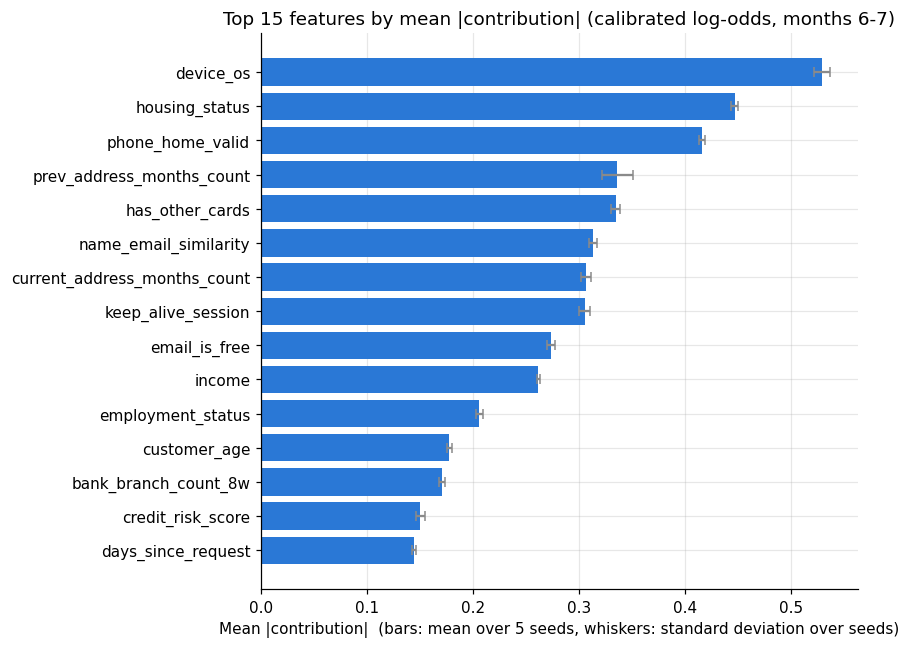

In [11]:
TOP = 15
top = importance_table.head(TOP).iloc[::-1]   # largest at the top of the chart

plt.figure(figsize=(8, 6))
plt.barh(top.index, top[MEAN], xerr=top['std over seeds'], color=BLUE, ecolor=GREY, capsize=3)
plt.title(f'Top {TOP} features by mean |contribution| (calibrated log-odds, months 6-7)')
plt.xlabel('Mean |contribution|  (bars: mean over 5 seeds, whiskers: standard deviation over seeds)')
plt.tight_layout()
plt.show()

**Beeswarm chart**
- Each dot is one application (a random sample of 5,000 test applications, with about 1.4% fraud)
- Position along the x-axis is the contribution of that feature to the calibrated log-odds: right pushes the score towards fraud, left towards genuine.
- Colour is the feature's value relative to other applications (blue = low, red = high; for categories, the order of the category list; grey = missing).

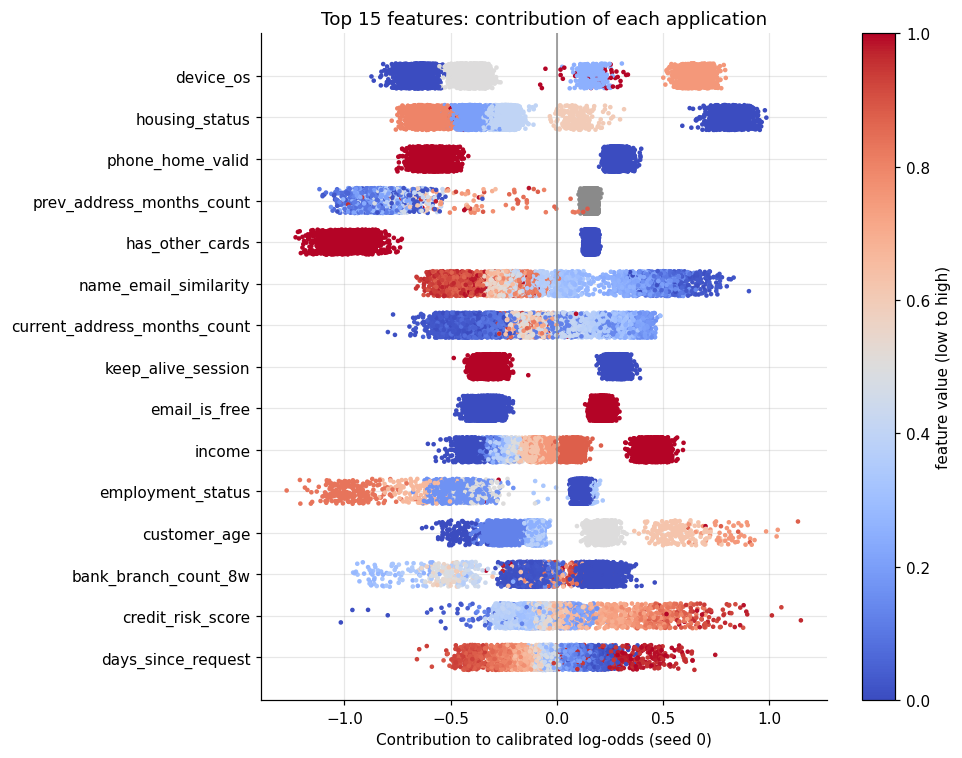

In [12]:
SAMPLE = min(5000, len(X_test))
rng = np.random.default_rng(0)
sample = rng.choice(len(X_test), size=SAMPLE, replace=False)
X_sample = X_test.iloc[sample]

top_features = list(importance_table.index[:TOP])[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
for position, feature in enumerate(top_features):
    x = shap_values[0][sample, FEATURE_NAMES.index(feature)] * A[0]
    column = X_sample[feature]
    if isinstance(column.dtype, pd.CategoricalDtype):
        column = column.cat.codes.astype(float)
    ranks = column.rank(method='dense')
    colour = ((ranks - 1) / (ranks.max() - 1)) if ranks.max() > 1 else ranks * 0 + 0.5
    colour = colour.to_numpy()
    y = position + rng.uniform(-0.3, 0.3, size=SAMPLE)
    known = ~np.isnan(colour)
    ax.scatter(x[~known], y[~known], color=GREY, s=4)
    dots = ax.scatter(x[known], y[known], c=colour[known], cmap='coolwarm', vmin=0, vmax=1, s=4)

ax.axvline(0, color=GREY, linewidth=1)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels(top_features)
ax.set_xlabel('Contribution to calibrated log-odds (seed 0)')
ax.set_title(f'Top {TOP} features: contribution of each application')
plt.colorbar(dots, ax=ax, label='feature value (low to high)')
plt.tight_layout()
plt.show()

**Key insights**
- **The explanations are trustworthy.** The contributions add up to the margin (largest difference 7e-6), the Platt mapping matches (4e-6), and no score was clipped. The seeds agree closely: the lowest rank correlation is 0.994, and 0.991 after grouping.
- **Importance is spread out.** device_os is the largest at 9.8% of the total. The top 7 features make up about 50% and 20 features make up 90%. No single feature dominates and none looks like a leak.
- **The velocity ratios barely matter** (importance 0.027-0.086). The model is not leaning on the features that drifted.
- **Age reaches the model through several proxies.** customer_age itself ranks 12, but device_os, housing_status, current_address_months_count and employment_status rank 1, 2, 7 and 11. Removing age alone will not remove age information, which matters for the fairness work.
- **Some columns contribute nothing.** Five of the 34 columns have a mean |contribution| below 0.0005: `source` (0.0004) and four missing flags (`bank_months_count_missing`, `session_length_in_minutes_missing`, `current_address_months_count_missing` and `device_distinct_emails_8w_missing`). One of them is exactly zero in every seed (the check in the output counts 1). This supports the decision to group each missing flag with its column in section 4: only 2 of the 6 flags carry any weight.

## **4. Grouped Importance**
### **4.1 Value + Missing Flag Together**
XGBoost sends missing values down a learned branch by itself, so a column and its `_missing` flag carry the same information, and the model can split the credit between them differently in every seed. They can also **cancel**: the flag can push up while the value pushes down. 

So each flag is added to its column **per application, before taking the absolute value**. The result is one importance per original column (28 groups instead of 34 features). The last column shows the importance the two would have had if they were simply added after taking absolute values (the section 3 way).

Result: **A value and its missing flag shared credit between them.** Only 2 of the 6 flags matter (prev_address and intended_balcon). Adding each flag to its column per application before taking the absolute value cut the seed spread of prev_address_months_count from ±0.014 to ±0.005.

In [13]:
FLAG_SUFFIX = '_missing'
groups = {name: [name] for name in FEATURE_NAMES if not name.endswith(FLAG_SUFFIX)}
for name in FEATURE_NAMES:
    if name.endswith(FLAG_SUFFIX):
        groups[name[:-len(FLAG_SUFFIX)]].append(name)
GROUP_NAMES = list(groups)
group_index = {group: [FEATURE_NAMES.index(member) for member in members] for group, members in groups.items()}

# one column per group: the contributions of its members added up for each application
grouped_shap = {seed: np.column_stack([shap_values[seed][:, index].sum(axis=1) for index in group_index.values()])
                for seed in SEEDS}

grouped = pd.DataFrame({seed: np.abs(grouped_shap[seed]).mean(axis=0) * A[seed] for seed in SEEDS}, index=GROUP_NAMES)
grouped_importance = pd.DataFrame({MEAN: grouped.mean(axis=1), 'std over seeds': grouped.std(axis=1)})
grouped_importance['share of total'] = grouped_importance[MEAN] / grouped_importance[MEAN].sum()
grouped_importance['members added separately'] = [importance_table.loc[groups[g], MEAN].sum()
                                                  for g in grouped_importance.index]
grouped_importance = grouped_importance.sort_values(MEAN, ascending=False)
grouped_importance['cumulative share'] = grouped_importance['share of total'].cumsum()

grouped_correlation = grouped.rank(ascending=False).corr(method='spearman')
lowest = grouped_correlation.to_numpy()[~np.eye(len(SEEDS), dtype=bool)].min()
print(f'Lowest Spearman correlation between two seeds\' grouped rankings: {lowest:.3f}')
print('Groups with a missing flag:', [g for g, members in groups.items() if len(members) > 1])
grouped_importance.round(4)

Lowest Spearman correlation between two seeds' grouped rankings: 0.991
Groups with a missing flag: ['prev_address_months_count', 'current_address_months_count', 'intended_balcon_amount', 'bank_months_count', 'session_length_in_minutes', 'device_distinct_emails_8w']


,mean |contribution|,std over seeds,share of total,members added separately,cumulative share
device_os,0.5286,0.0074,0.0982,0.5286,0.0982
housing_status,0.4467,0.0032,0.0830,0.4467,0.1812
phone_home_valid,0.4162,0.0028,0.0773,0.4162,0.2585
prev_address_months_count,0.3902,0.0049,0.0725,0.3903,0.3309
has_other_cards,0.3343,0.0045,0.0621,0.3343,0.3930
name_email_similarity,0.3131,0.0036,0.0582,0.3131,0.4512
current_address_months_count,0.3062,0.0044,0.0569,0.3063,0.5081
keep_alive_session,0.3051,0.0048,0.0567,0.3051,0.5648
email_is_free,0.2735,0.0035,0.0508,0.2735,0.6156
income,0.2614,0.0016,0.0485,0.2614,0.6641


### **4.2 Correlated Pairs**
- With correlated pairs, each features can look less important than the pair together.
- Contributions of a pair are added per application before taking the absolute value. A pair with a low correlation would not need grouping.
- Credit pair: credit_risk_score and proposed_credit_limit are related (Spearman 0.63). As a pair, they have importance 0.209, 3.9% of the total, rank 11 of 27. Separately each looks weaker (ranks 14 and 21), so quote the pair-wise rank. The pair is smaller than the two added separately (0.209 against 0.238) because their contributions partly cancel, which fits the finding in 7.1 and 7.2 that the model uses the credit limit as a correction to the risk score.
- Address pair: prev and current address times are almost unrelated, and both are strong separate signals (importance 0.390 and 0.306, together about 13% of the total). They were not grouped.

In [49]:
PAIRS = [('credit_risk_score', 'proposed_credit_limit')]
merged_importance = grouped_importance[MEAN].copy()
rows = []
for first, second in PAIRS:
    i, j = GROUP_NAMES.index(first), GROUP_NAMES.index(second)
    pair_importance = np.mean([np.abs(grouped_shap[seed][:, i] + grouped_shap[seed][:, j]).mean() * A[seed] for seed in SEEDS])
    merged_importance = merged_importance.drop([first, second])
    merged_importance[f'{first} + {second}'] = pair_importance
    rows.append({'pair': f'{first} + {second}',
                 'Spearman correlation (months 6-7)': X_test[first].corr(X_test[second], method='spearman'),
                 'importance of the first': grouped_importance.loc[first, MEAN],
                 'importance of the second': grouped_importance.loc[second, MEAN],
                 'the two added after |.|': grouped_importance.loc[first, MEAN] + grouped_importance.loc[second, MEAN],
                 'the pair added before |.|': pair_importance,
                 'share of total importance': pair_importance / grouped_importance[MEAN].sum()})
pair_table = pd.DataFrame(rows).set_index('pair')
ranks_with_pairs = merged_importance.rank(ascending=False).astype(int)
pair_table['rank as a pair'] = [ranks_with_pairs[name] for name in pair_table.index]
pair_table.round(4)

,Spearman correlation (months 6-7),importance of the first,importance of the second,the two added after |.|,the pair added before |.|,share of total importance,rank as a pair
pair,,,,,,,
credit_risk_score + proposed_credit_limit,0.6332,0.1501,0.0883,0.2384,0.2093,0.0389,11


## **5. Permutation Importance on the Real Metric**
- SHAP = how much a feature moves the **score**.
- Permutation importance = how much the model's **performance** falls when the feature is scrambled, which is what matters for catching fraud.
- For each group of columns, the values are shuffled together (so a value and its flag stay consistent) `N_REPEATS` times across the test applications, the model scores them again, and we record the drop in two metrics (averaged over repeats and seeds):
    - **recall at 5% FPR** (main metric of notebook 02)
    - **PR-AUC**
- The same test rows are used every time, so the drops are comparable between groups.
- A drop near 0 (or slightly negative) means the model gets nothing from that group on these months.

**Results**
- Top two: housing_status (recall at 5% FPR drops 0.074) and device_os (0.068), from a baseline of 0.548. Then phone_home_valid (0.050) and has_other_cards (0.045).
- Eight groups barely matter, with drops under 0.004: the three velocity ratios, payment_type, source, phone_mobile_valid, foreign_request and session_length. `velocity_24h_vs_4w` is slightly negative (-0.0015). This is in line with the drifted features not mattering.
- Customer age costs only about 0.011 recall, rank 14 of 28. This links to the fairness work: dropping age costs little accuracy.
- It agrees with SHAP (rank correlation 0.95 for recall), so the SHAP ranking can be trusted.

In [15]:
TARGET_FPR = 0.05   # at most 5% of genuine applications may be flagged


def recall_at_fpr(y_true, scores, target_fpr=TARGET_FPR):
    """Copied from notebook 02, section 2."""
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    i = np.searchsorted(fpr, target_fpr, side='right') - 1   # last point still within the budget
    return tpr[i]


def test_metrics(scores):
    return {'recall@5%FPR': recall_at_fpr(y_test, scores), 'PR-AUC': average_precision_score(y_test, scores)}


PERMUTATION_SEEDS = [0, 1, 2, 3, 4]
N_REPEATS = 3

permutation_rng = np.random.default_rng(1)
permutation_baseline = {}
rows = []
start = time.time()
for seed in PERMUTATION_SEEDS:
    model = models[seed]
    permutation_baseline[seed] = test_metrics(model.predict_proba(X_test)[:, 1])
    for group, members in groups.items():
        drops = []
        for repeat in range(N_REPEATS):
            order = permutation_rng.permutation(len(X_test))
            X_permuted = X_test.copy()
            for column in members:
                X_permuted[column] = X_test[column].values[order]   # the same shuffle for a value and its flag
            permuted = test_metrics(model.predict_proba(X_permuted)[:, 1])
            drops.append({m: permutation_baseline[seed][m] - permuted[m] for m in permuted})
        drops = pd.DataFrame(drops)
        rows.append({'seed': seed, 'group': group,
                     'recall@5%FPR drop': drops['recall@5%FPR'].mean(), 'recall drop (std)': drops['recall@5%FPR'].std(),
                     'PR-AUC drop': drops['PR-AUC'].mean(), 'PR-AUC drop (std)': drops['PR-AUC'].std()})
    print(f'seed {seed} done, {(time.time() - start) / 60:.1f} min so far')

permutation_rows = pd.DataFrame(rows)
by_group = permutation_rows.groupby('group')
permutation_importance = pd.DataFrame({
    'recall@5%FPR drop': by_group['recall@5%FPR drop'].mean(),
    'recall drop (std over seeds)': by_group['recall@5%FPR drop'].std(),
    'PR-AUC drop': by_group['PR-AUC drop'].mean(),
    'PR-AUC drop (std over seeds)': by_group['PR-AUC drop'].std(),
}).sort_values('recall@5%FPR drop', ascending=False)
print('Unshuffled test metrics (mean over seeds):',
      {m: round(float(np.mean([permutation_baseline[s][m] for s in PERMUTATION_SEEDS])), 4) for m in ['recall@5%FPR', 'PR-AUC']})
permutation_importance.round(4)

seed 0 done, 0.6 min so far
seed 1 done, 1.1 min so far
seed 2 done, 1.7 min so far
seed 3 done, 2.4 min so far
seed 4 done, 3.0 min so far
Unshuffled test metrics (mean over seeds): {'recall@5%FPR': 0.5482, 'PR-AUC': 0.1968}


,recall@5%FPR drop,recall drop (std over seeds),PR-AUC drop,PR-AUC drop (std over seeds)
group,,,,
housing_status,0.0741,0.0039,0.0448,0.0009
device_os,0.0681,0.0026,0.0426,0.0021
phone_home_valid,0.0497,0.0044,0.0305,0.0019
has_other_cards,0.0445,0.0042,0.0217,0.0022
name_email_similarity,0.0324,0.0025,0.0184,0.0019
prev_address_months_count,0.0298,0.0026,0.0169,0.0012
email_is_free,0.0262,0.0019,0.0149,0.0015
keep_alive_session,0.0250,0.0038,0.0180,0.0009
employment_status,0.0193,0.0016,0.0108,0.0008


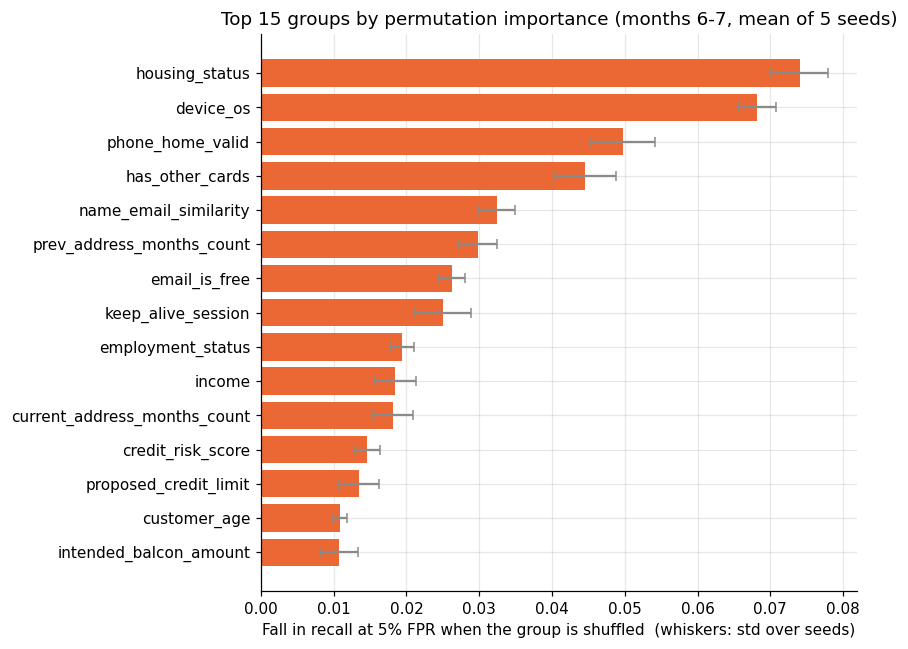

In [16]:
top = permutation_importance.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top['recall@5%FPR drop'], xerr=top['recall drop (std over seeds)'], color=ORANGE, ecolor=GREY, capsize=3)
plt.axvline(0, color=GREY, linewidth=1)
plt.title('Top 15 groups by permutation importance (months 6-7, mean of 5 seeds)')
plt.xlabel('Fall in recall at 5% FPR when the group is shuffled  (whiskers: std over seeds)')
plt.tight_layout()
plt.show()

## **6. Comparing the Importance Methods**
Four rankings of the same 28 groups:
- **SHAP**: mean |contribution| of the group,
- **permutation (recall)** and **permutation (PR-AUC)**: the fall in performance when the group is shuffled,
- **single-feature AUC**: how well the column separates fraud on its own, on the training months 0-3 with the missing values left out (rows with a missing value are skipped; categories are replaced by their fraud rate, as in the EDA).

The correlation table at the bottom compares the rankings (1 = identical order).

**Results**
- SHAP and permutation agree. The Spearman correlation is 0.95 with the recall version and 0.93 with PR-AUC, and the two permutation rankings agree at 0.98. The model depends on the features it moves the score with, so the top of the list can be trusted.
- Single-feature AUC agrees much less (0.60 to 0.66 with the others). Knowing how well a column predicts fraud alone is a poor guide to what the model uses.
- Features the model uses more than single-feature AUC suggests:
    - phone_home_valid is rank 3 by SHAP and permutation but 16 by AUC.
    - has_other_cards is rank 5, 4 and 4 against 17 by AUC.
    - email_is_free is rank 9, 7 and 8 against 18 by AUC.
    - These are binary columns, with a low single-feature AUC because they are weak alone but give clear splits in combination.
- Features that look strong alone but matter less to the model:
    - customer_age is rank 3 by AUC but 12–15 by the others.
    - credit_risk_score is rank 4 by AUC but 12–14 by the others.
    - proposed_credit_limit is rank 6 by AUC and 21 by SHAP, but 10–13 by permutation.
    - These are correlated with other features (credit risk with credit limit, age with its proxies), so the model gets the information from elsewhere.
- The top two are the same everywhere: housing_status and device_os are rank 1–2 in all four rankings.
- The velocity ratios rank low in all four rankings (SHAP 22, 23 and 25; permutation 21-28), so the features that drifted aren't driving the model.
- proposed_credit_limit is the clearest case where SHAP and permutation disagree (rank 21 against 10–13), and it is one of the correlated pairs.

**Caveats**
- The single-feature AUC is computed on the training months 0–3, and the others on test months 6–7, so part of the difference could come from the period.

In [17]:
train = base[base['month'].isin([0, 1, 2, 3])]
X_train = make_features(train, **FEATURES)
y_train = train[TARGET].to_numpy()
CATEGORICAL_GROUPS = [g for g in GROUP_NAMES if isinstance(X_test[g].dtype, pd.CategoricalDtype)]


def single_feature_auc(values, y, categorical=False):
    """AUC of one column on its own. Missing values are skipped. Categories are replaced by their fraud rate."""
    values = values.reset_index(drop=True)
    y = pd.Series(y)
    if categorical:
        rate = y.groupby(values, observed=True).mean().to_dict()
        score = values.astype(object).map(rate).astype(float)
    else:
        score = values.astype(float)
    keep = np.isfinite(score)
    return roc_auc_score(y[keep], score[keep])


single_auc = pd.Series({g: single_feature_auc(X_train[g], y_train, g in CATEGORICAL_GROUPS) for g in GROUP_NAMES})
single_strength = np.maximum(single_auc, 1 - single_auc)   # an AUC of 0.3 is as useful as 0.7, just reversed

comparison = pd.DataFrame({
    'SHAP rank': grouped_importance[MEAN].rank(ascending=False, method='min'),
    'permutation rank (recall)': permutation_importance['recall@5%FPR drop'].rank(ascending=False, method='min'),
    'permutation rank (PR-AUC)': permutation_importance['PR-AUC drop'].rank(ascending=False, method='min'),
    'single-feature AUC rank': single_strength.rank(ascending=False, method='min'),
}).astype(int).sort_values('SHAP rank')
comparison['single-feature AUC'] = single_strength.round(3)

print('Spearman correlation between the rankings:')
print(comparison.drop(columns='single-feature AUC').corr(method='spearman').round(2).to_string())
comparison

Spearman correlation between the rankings:
                           SHAP rank  permutation rank (recall)  permutation rank (PR-AUC)  single-feature AUC rank
SHAP rank                       1.00                       0.95                       0.93                     0.60
permutation rank (recall)       0.95                       1.00                       0.98                     0.64
permutation rank (PR-AUC)       0.93                       0.98                       1.00                     0.66
single-feature AUC rank         0.60                       0.64                       0.66                     1.00


,SHAP rank,permutation rank (recall),permutation rank (PR-AUC),single-feature AUC rank,single-feature AUC
device_os,1,2,2,2,0.687
housing_status,2,1,1,1,0.710
phone_home_valid,3,3,3,16,0.566
prev_address_months_count,4,6,7,13,0.580
has_other_cards,5,4,4,17,0.565
name_email_similarity,6,5,5,11,0.595
current_address_months_count,7,11,11,5,0.639
keep_alive_session,8,8,6,9,0.618
email_is_free,9,7,8,18,0.561
income,10,10,9,8,0.629


## **7. Feature Effects: Direction and Shape**
### **7.1 Direction Check: the Data vs the Model**
Does each feature push towards fraud in the model the same way it does in the data?
- **raw (EDA style)**: AUC on the raw column from months 0-3, with the hidden `-1` / negative missing codes counted as ordinary (lowest) values, exactly as the EDA's single-feature AUC table did,
- **cleaned**: the same AUC, but only on applications where the value is present,
- **model**: Spearman correlation between the feature's value and its own contribution on the test months, among applications where the value is present (positive: higher value pushes towards fraud).

Directions closer to "no relationship" than a small threshold (AUC within 0.02 of 0.5, |Spearman| under 0.1) are called *unclear* (Numbers are conventions, not tuned). A feature can be unclear because it has no effect or because its effect is not monotone (for example U-shaped), so unclear ones need the dependence plots.

**Results**
- The model agrees with the cleaned data for 22 of 23 numeric features. Examples: income (+0.98), customer_age (+0.81), credit_risk_score (+0.46) push towards fraud, and phone_home_valid (-0.86) and has_other_cards (-0.72) push away.
- The −1 codes distorted three EDA directions: prev_address_months_count, bank_months_count and intended_balcon_amount. In the EDA, “higher → less fraud” came from the −1s. Among real values, higher means more fraud.
- One real disagreement: proposed_credit_limit. The data says higher → more fraud (AUC 0.632). The model says higher → less fraud (−0.19). The likely reason is its correlation with credit_risk_score, so the model uses it as a correction to the risk score. Section 7.2 looks into this.
- Unclear cases: intended_balcon_amount (−0.096) and session_length (−0.087). These need the dependence plots.

In [18]:
NUMERIC_GROUPS = [g for g in GROUP_NAMES if g not in CATEGORICAL_GROUPS]


def direction(strength, threshold):
    """+1 (higher value, more fraud), -1 (higher value, less fraud), 0 (unclear)."""
    if np.isnan(strength) or abs(strength) < threshold:
        return 0
    return 1 if strength > 0 else -1


NAMES = {1: 'higher -> more fraud', -1: 'higher -> less fraud', 0: 'unclear'}
rows = []
for group in NUMERIC_GROUPS:
    column = X_test[group].to_numpy(dtype=float)
    contribution = shap_values[0][:, FEATURE_NAMES.index(group)]
    present = ~np.isnan(column)
    spearman = pd.Series(column[present]).corr(pd.Series(contribution[present]), method='spearman')

    raw_auc = roc_auc_score(y_train, train[group]) if group in train.columns else np.nan
    cleaned_auc = single_auc[group]

    raw_dir = direction(raw_auc - 0.5, 0.02)
    cleaned_dir = direction(cleaned_auc - 0.5, 0.02)
    model_dir = direction(spearman, 0.1)
    rows.append({
        'feature': group,
        'raw AUC': raw_auc, 'raw direction': NAMES[raw_dir] if group in train.columns else '',
        'cleaned AUC': cleaned_auc, 'cleaned direction': NAMES[cleaned_dir],
        'model Spearman': spearman, 'model direction': NAMES[model_dir],
        'raw differs from cleaned': bool(group in train.columns and raw_dir != 0 and cleaned_dir != 0 and raw_dir != cleaned_dir),
        'cleaned differs from model': bool(cleaned_dir != 0 and model_dir != 0 and cleaned_dir != model_dir),
    })

direction_table = pd.DataFrame(rows).set_index('feature').loc[[g for g in grouped_importance.index if g in NUMERIC_GROUPS]]
print('Raw differs from cleaned:', list(direction_table.index[direction_table['raw differs from cleaned']]))
print('Cleaned differs from model:', list(direction_table.index[direction_table['cleaned differs from model']]))
direction_table.round(3)

Raw differs from cleaned: ['prev_address_months_count', 'bank_months_count', 'intended_balcon_amount']
Cleaned differs from model: ['proposed_credit_limit']


,raw AUC,raw direction,cleaned AUC,cleaned direction,model Spearman,model direction,raw differs from cleaned,cleaned differs from model
feature,,,,,,,,
phone_home_valid,0.434,higher -> less fraud,0.434,higher -> less fraud,-0.864,higher -> less fraud,False,False
prev_address_months_count,0.389,higher -> less fraud,0.580,higher -> more fraud,0.374,higher -> more fraud,True,False
has_other_cards,0.435,higher -> less fraud,0.435,higher -> less fraud,-0.715,higher -> less fraud,False,False
name_email_similarity,0.405,higher -> less fraud,0.405,higher -> less fraud,-0.851,higher -> less fraud,False,False
current_address_months_count,0.640,higher -> more fraud,0.639,higher -> more fraud,0.643,higher -> more fraud,False,False
keep_alive_session,0.382,higher -> less fraud,0.382,higher -> less fraud,-0.846,higher -> less fraud,False,False
email_is_free,0.561,higher -> more fraud,0.561,higher -> more fraud,0.866,higher -> more fraud,False,False
income,0.629,higher -> more fraud,0.629,higher -> more fraud,0.977,higher -> more fraud,False,False
customer_age,0.662,higher -> more fraud,0.662,higher -> more fraud,0.806,higher -> more fraud,False,False


### **7.2 The Credit Limit: Data vs Model**
- To settle a contradiction in section 7.1. In the data, a higher `proposed_credit_limit` goes with more fraud (single-feature AUC 0.63), but section 7.1 reported a negative Spearman correlation between the limit and the model’s contribution, which looked like the model reversing the effect.
- The limit takes only a few distinct values, with most applications at the lowest ones, so a rank correlation is dominated by ties and isn’t reliable. This section therefore looks at each limit value directly: the fraud rate per limit (within bands of credit risk score, since the two are correlated at 0.64), and the model’s average contribution per limit. The limits are then grouped into 5 clusters (190–210, 490–510, 990–1000, 1500, 1900–2100) to make the shape readable.
- 4 risk bands (quarters): gives a few large bands; cells with fewer than 300 applications blank as 300 is a floor against the noisiest cells; at a 1% fraud rate even 300 applications hold only about 3 fraud cases, so cells with few hundred applications are still noisy.

**Results**
- The model agrees with the data. The contribution is flat or slightly negative up to 1,000 (−0.07 to −0.17), +0.08 at 1,500, and about +1.1 to +1.2 at 1,900 and above. Fraud follows the same shape, from 0.65% in the 190–210 cluster to 1.85% at 1,500 and 11.7% at 1,900–2,100. The negative Spearman was an artefact, not a model error.

In [19]:
risk_band = pd.qcut(X_train['credit_risk_score'], 4, duplicates='drop')
frame = pd.DataFrame({'limit': X_train['proposed_credit_limit'], 'band': risk_band, 'fraud': y_train})

rate = frame.pivot_table(index='limit', columns='band', values='fraud', aggfunc='mean', observed=True) * 100
count = frame.pivot_table(index='limit', columns='band', values='fraud', aggfunc='size', observed=True)
rate = rate.where(count >= 300)
rate.columns = [f'risk band {band}' for band in rate.columns]
rate['all risk bands'] = frame.groupby('limit')['fraud'].mean() * 100
rate['rows'] = frame.groupby('limit').size()
limit_contribution = pd.Series(grouped_shap[0][:, GROUP_NAMES.index('proposed_credit_limit')] * A[0])
rate['model: mean contribution (months 6-7)'] = limit_contribution.groupby(X_test['proposed_credit_limit'].to_numpy()).mean()

corr = X_train['proposed_credit_limit'].corr(X_train['credit_risk_score'], method='spearman')
print(f'Spearman correlation between credit limit and credit risk score (months 0-3): {corr:.2f}')
rate.round(3)

Spearman correlation between credit limit and credit risk score (months 0-3): 0.64


,"risk band (-170.001, 69.0]","risk band (69.0, 113.0]","risk band (113.0, 171.0]","risk band (171.0, 389.0]",all risk bands,rows,model: mean contribution (months 6-7)
limit,,,,,,,
190.0,NaN,NaN,NaN,NaN,0.000,78,-0.066
200.0,0.565,0.629,0.633,1.510,0.648,338607,-0.066
210.0,NaN,NaN,NaN,NaN,0.000,359,-0.104
490.0,NaN,NaN,NaN,NaN,1.136,264,-0.095
500.0,0.726,0.573,0.689,1.311,0.865,61935,-0.098
510.0,NaN,0.000,0.352,0.646,0.368,3803,-0.159
990.0,NaN,NaN,0.669,1.344,1.065,3004,-0.169
1000.0,0.512,0.637,0.731,1.064,0.908,38445,-0.163
1500.0,0.941,1.074,1.178,2.119,1.851,98632,0.076


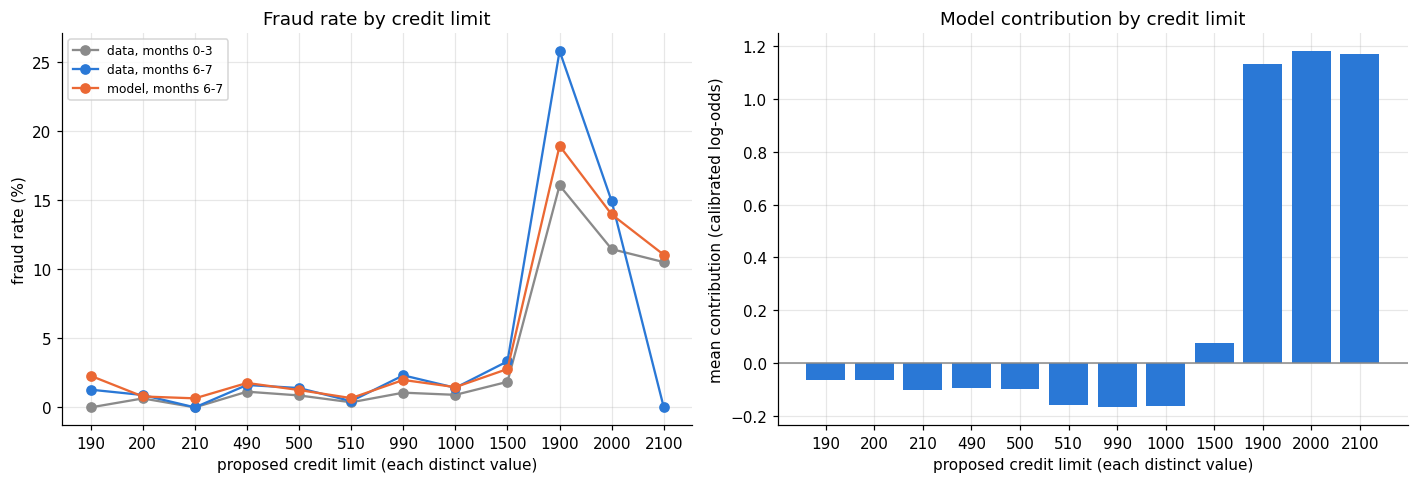

,share of applications (months 0-3),fraud rate months 0-3 (%),fraud rate months 6-7 (%),model mean probability months 6-7 (%),model mean contribution (calibrated log-odds)
limit,,,,,
190.0,0.000,0.000,1.282,2.288,-0.066
200.0,0.618,0.648,0.896,0.791,-0.066
210.0,0.001,0.000,0.000,0.654,-0.104
490.0,0.000,1.136,1.623,1.769,-0.095
500.0,0.113,0.865,1.400,1.256,-0.098
510.0,0.007,0.368,0.451,0.671,-0.159
990.0,0.005,1.065,2.321,1.987,-0.169
1000.0,0.070,0.908,1.418,1.466,-0.163
1500.0,0.180,1.851,3.338,2.780,0.076


In [20]:
limits = np.sort(X_train['proposed_credit_limit'].dropna().unique())
contribution_array = limit_contribution.to_numpy()
rows = []
for limit in limits:
    in_train = (X_train['proposed_credit_limit'] == limit).to_numpy()
    in_test = (X_test['proposed_credit_limit'] == limit).to_numpy()
    rows.append({'limit': limit,
                 'share of applications (months 0-3)': in_train.mean(),
                 'fraud rate months 0-3 (%)': y_train[in_train].mean() * 100,
                 'fraud rate months 6-7 (%)': y_test[in_test].mean() * 100 if in_test.any() else np.nan,
                 'model mean probability months 6-7 (%)': calibrated_test[in_test].mean() * 100 if in_test.any() else np.nan,
                 'model mean contribution (calibrated log-odds)': contribution_array[in_test].mean() if in_test.any() else np.nan})
limit_table = pd.DataFrame(rows).set_index('limit')

positions = np.arange(len(limits))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(positions, limit_table['fraud rate months 0-3 (%)'], 'o-', color=GREY, label='data, months 0-3')
axes[0].plot(positions, limit_table['fraud rate months 6-7 (%)'], 'o-', color=BLUE, label='data, months 6-7')
axes[0].plot(positions, limit_table['model mean probability months 6-7 (%)'], 'o-', color=ORANGE, label='model, months 6-7')
axes[0].set_ylabel('fraud rate (%)')
axes[0].legend(fontsize=8)
axes[1].bar(positions, limit_table['model mean contribution (calibrated log-odds)'], color=BLUE)
axes[1].axhline(0, color=GREY, linewidth=1)
axes[1].set_ylabel('mean contribution (calibrated log-odds)')
for ax, title in zip(axes, ['Fraud rate by credit limit', 'Model contribution by credit limit']):
    ax.set_xticks(positions)
    ax.set_xticklabels([f'{limit:.0f}' for limit in limits])
    ax.set_xlabel('proposed credit limit (each distinct value)')
    ax.set_title(title)
plt.tight_layout()
plt.show()
limit_table.round(3)

In [21]:
CLUSTERS = {'190-210': [190, 200, 210], '490-510': [490, 500, 510], '990-1000': [990, 1000], '1500': [1500], '1900-2100': [1900, 2000, 2100]}
cluster_of = {value: name for name, values in CLUSTERS.items() for value in values}
train_cluster = X_train['proposed_credit_limit'].map(cluster_of)
test_cluster = X_test['proposed_credit_limit'].map(cluster_of)
cluster_table = pd.DataFrame({
    'applications, months 6-7': test_cluster.value_counts(),
    'fraud rate months 0-3 (%)': pd.Series(y_train).groupby(train_cluster.to_numpy()).mean() * 100,
    'fraud rate months 6-7 (%)': pd.Series(y_test).groupby(test_cluster.to_numpy()).mean() * 100,
    'model mean probability months 6-7 (%)': pd.Series(calibrated_test).groupby(test_cluster.to_numpy()).mean() * 100,
    'model mean contribution': pd.Series(contribution_array).groupby(test_cluster.to_numpy()).mean(),
}).reindex(list(CLUSTERS))
print('Limits not in any cluster:', sorted(set(limits) - set(cluster_of)))
cluster_table.round(3)

Limits not in any cluster: []


,"applications, months 6-7",fraud rate months 0-3 (%),fraud rate months 6-7 (%),model mean probability months 6-7 (%),model mean contribution
190-210,125061,0.647,0.896,0.791,-0.066
490-510,35674,0.838,1.379,1.249,-0.099
990-1000,24165,0.919,1.544,1.539,-0.164
1500,18366,1.851,3.338,2.780,0.076
1900-2100,1745,11.692,16.046,14.492,1.177


### **7.3 Dependence Plots for the Numeric Features**
- To show the shape of each effect: a feature’s value on the x-axis against its contribution on the y-axis, for the 8 most important numeric features. A direction check tells you “up or down”, and this shows whether it is a smooth line, a step or a U-shape. Spread above and below the average line shows interactions with other features.
- Choices to ensure charts are readable: 8 most important numeric features, 40 bins between the 1st and 99th percentile, bins with fewer than 30 sampled applications dropped, log axis when the 99th percentile is over 100x the 1st

**Results**
- Age rises steadily from about −0.47 at 10 to about +0.57 at 60, flat between 30 and 40.
- Missing values have their own effect, shown by the dashed line: a missing `prev_address_months_count` (70% of rows) sits at +0.18 while present values sit around −0.8 to −1.0, and a missing `current_address_months_count` (1%) sits at −0.37. This is why a value and its flag were grouped.
- Several effects are step-like or non-monotone: `current_address_months_count` jumps from about −0.4 to +0.4 between 30 and 60 months and falls back to about −0.1 after 170 months; `bank_branch_count_8w` drops to about −0.85 at 250-500 and recovers above 1,250; `days_since_request` dips around 0.04 days and rises again; `credit_risk_score` is flat until about 230 and then climbs to +0.7; income has a jump of about +0.5 at 0.9.

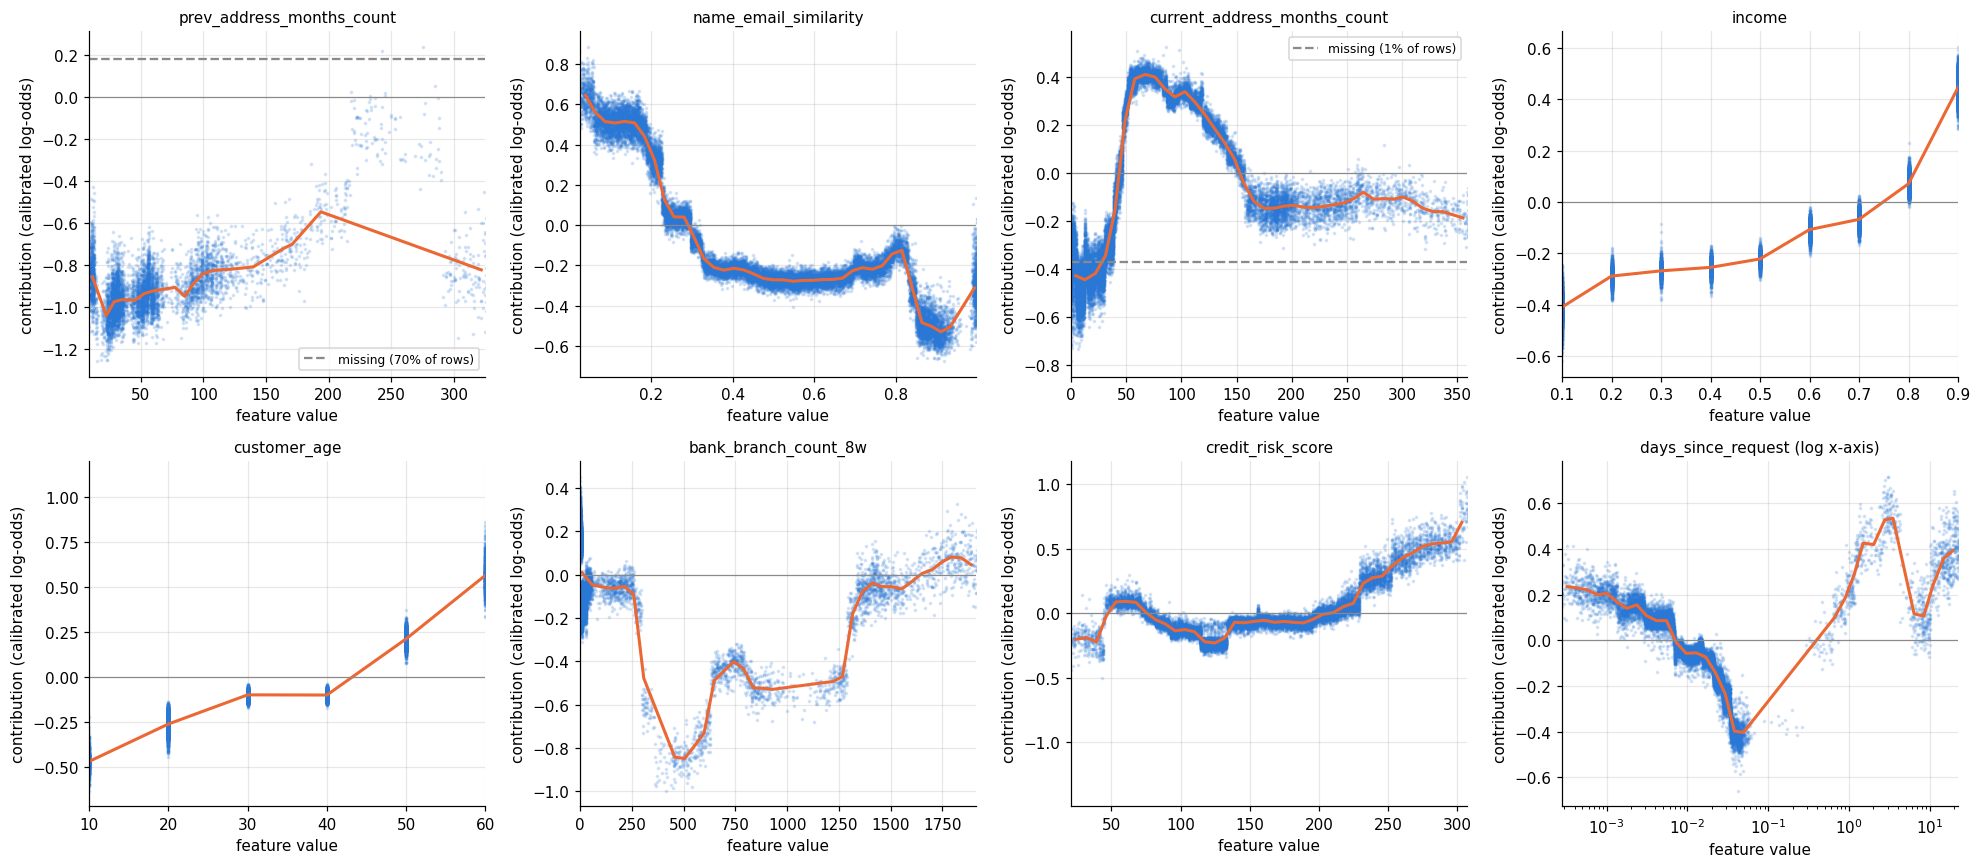

In [22]:
N_DEPENDENCE = 20000
dependence_rng = np.random.default_rng(3)
dependence_sample = dependence_rng.choice(len(X_test), size=min(N_DEPENDENCE, len(X_test)), replace=False)

numeric_top = [g for g in grouped_importance.index
               if g in NUMERIC_GROUPS and X_test[g].nunique() > 2][:8]


def binned_means(x, c, low, high, use_log, bins=40, min_count=30):
    """Average contribution per bin: at each value for few-valued features, else in equal-width (or log-spaced) bins."""
    frame = pd.DataFrame({'x': x, 'c': c}).dropna(subset=['x'])
    if frame['x'].nunique() <= 12:
        key = frame['x'].rename('bin')
    else:
        edges = np.geomspace(low, high, bins + 1) if use_log else np.linspace(low, high, bins + 1)
        frame = frame[(frame['x'] >= low) & (frame['x'] <= high)]
        key = pd.cut(frame['x'], edges, include_lowest=True).rename('bin')
    means = frame.groupby(key, observed=True).agg(x=('x', 'mean'), c=('c', 'mean'), n=('c', 'size'))
    means = means[means['n'] >= min_count]
    return means['x'].to_numpy(), means['c'].to_numpy()


fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, group in zip(axes.flatten(), numeric_top):
    x = X_test[group].to_numpy(dtype=float)[dependence_sample]
    c = grouped_shap[0][dependence_sample, GROUP_NAMES.index(group)] * A[0]
    known = x[~np.isnan(x)]
    low, high = np.percentile(known, [1, 99])
    use_log = bool(known.min() > 0 and high / low > 100)   # spans orders of magnitude
    ax.scatter(x, c, s=2, alpha=0.15, color=BLUE)
    line_x, line_c = binned_means(x, c, low, high, use_log)
    ax.plot(line_x, line_c, color=ORANGE, linewidth=2)
    if np.isnan(x).any():
        ax.axhline(c[np.isnan(x)].mean(), color=GREY, linestyle='--', linewidth=1.5,
                   label=f'missing ({np.isnan(x).mean():.0%} of rows)')
        ax.legend(loc='best', fontsize=8)
    if use_log:
        ax.set_xscale('log')
    ax.set_xlim(low, high)
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.set_title(group + (' (log x-axis)' if use_log else ''), fontsize=10)
    ax.set_xlabel('feature value')
    ax.set_ylabel('contribution (calibrated log-odds)')
for ax in axes.flatten()[len(numeric_top):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**The three ratio features.** All three stay within about ±0.2 in contribution, matching their low importance: `zip_count_vs_velocity_4w` steps from about −0.2 to +0.1 near 0.3, `velocity_24h_vs_4w` falls to about −0.2 above 1.6, and `velocity_6h_vs_24h` stays near 0 apart from a spike at about 2.6.

                          importance rank (of 28)  share of total importance
velocity_6h_vs_24h                             25                     0.0050
velocity_24h_vs_4w                             23                     0.0146
zip_count_vs_velocity_4w                       22                     0.0159


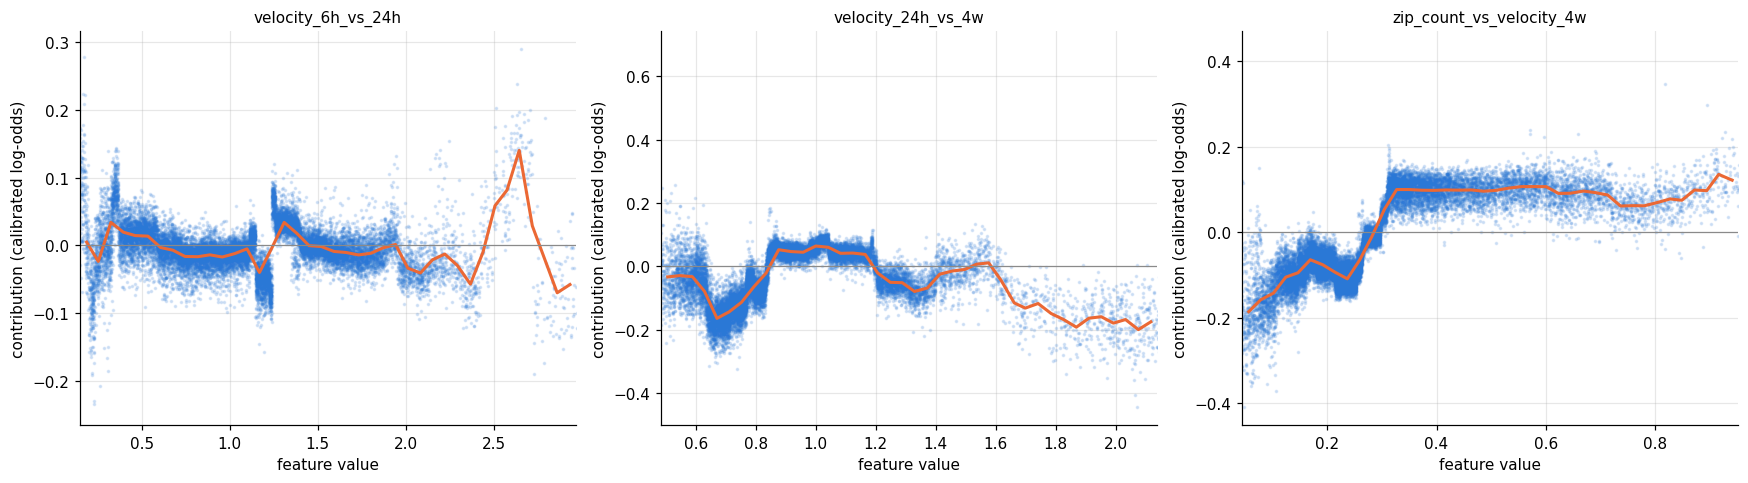

In [23]:
VELOCITY_RATIOS = ['velocity_6h_vs_24h', 'velocity_24h_vs_4w', 'zip_count_vs_velocity_4w']
ratio_rank = pd.DataFrame({'importance rank (of 28)': [grouped_importance.index.get_loc(g) + 1 for g in VELOCITY_RATIOS],
                           'share of total importance': [grouped_importance.loc[g, 'share of total'] for g in VELOCITY_RATIOS]},
                          index=VELOCITY_RATIOS)
print(ratio_rank.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, group in zip(axes, VELOCITY_RATIOS):
    x = X_test[group].to_numpy(dtype=float)[dependence_sample]
    c = grouped_shap[0][dependence_sample, GROUP_NAMES.index(group)] * A[0]
    finite = np.isfinite(x)
    low, high = np.percentile(x[finite], [1, 99])
    ax.scatter(x[finite], c[finite], s=2, alpha=0.15, color=BLUE)
    line_x, line_c = binned_means(x[finite], c[finite], low, high, False)
    ax.plot(line_x, line_c, color=ORANGE, linewidth=2)
    ax.set_xlim(low, high)
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.set_title(group, fontsize=10)
    ax.set_xlabel('feature value')
    ax.set_ylabel('contribution (calibrated log-odds)')
plt.tight_layout()
plt.show()

### **7.4 Do the Irregular Effects Hold in the Data?**
- Some dependence plots are irregular (`bank_branch_count_8w`, `days_since_request`, and the up-and-down shape of `current_address_months_count`). Irregular can mean real structure or overfitting. Is the **fraud rate itself** irregular in the same places, and in both the training months (0-3) and the test months (6-7)?
- For each feature, the applications are put into 25 bins with equal numbers of applications (pooling both periods), and the plot shows the **fraud rate in each bin** for months 0-3 (grey) and months 6-7 (blue), with one standard error, next to the model's **mean calibrated probability** on months 6-7 (orange). If the grey and blue curves have the same shape, the irregularity is real, and the orange curve should follow them. The table gives the Spearman correlation between the curves over the bins.
- 25 equal-count bins, with the same edges for both periods: Equal counts give about 300 fraud cases per bin (the standard error of a bin's rate is about 6% of the rate). Using the same edges makes the two periods comparable.

**Results**
- The shapes hold in both periods, and the model follows them, so the irregularities are real and not overfitting. Spearman correlation between the months 0-3 and 6-7 curves is 0.90 (`bank_branch_count_8w`), 0.81 (`days_since_request`), 0.97 (`current_address_months_count`) and 0.71 (`credit_risk_score`); between the data and the model it is 0.90, 0.89, 0.96 and 0.68.
- `credit_risk_score` agrees least, because its curve is flat below about 150 and only rises steeply above 230, so ranks within the flat part are noise. At the top the model is a little below the data (about 5.1% against 5.8% in the last bin).
- Fraud rates in months 6-7 are higher than in months 0-3 in nearly every panel, and the model’s curve sits above the months 0-3 curve and close to the months 6-7 curve, which is the same level shift seen in the drift table.

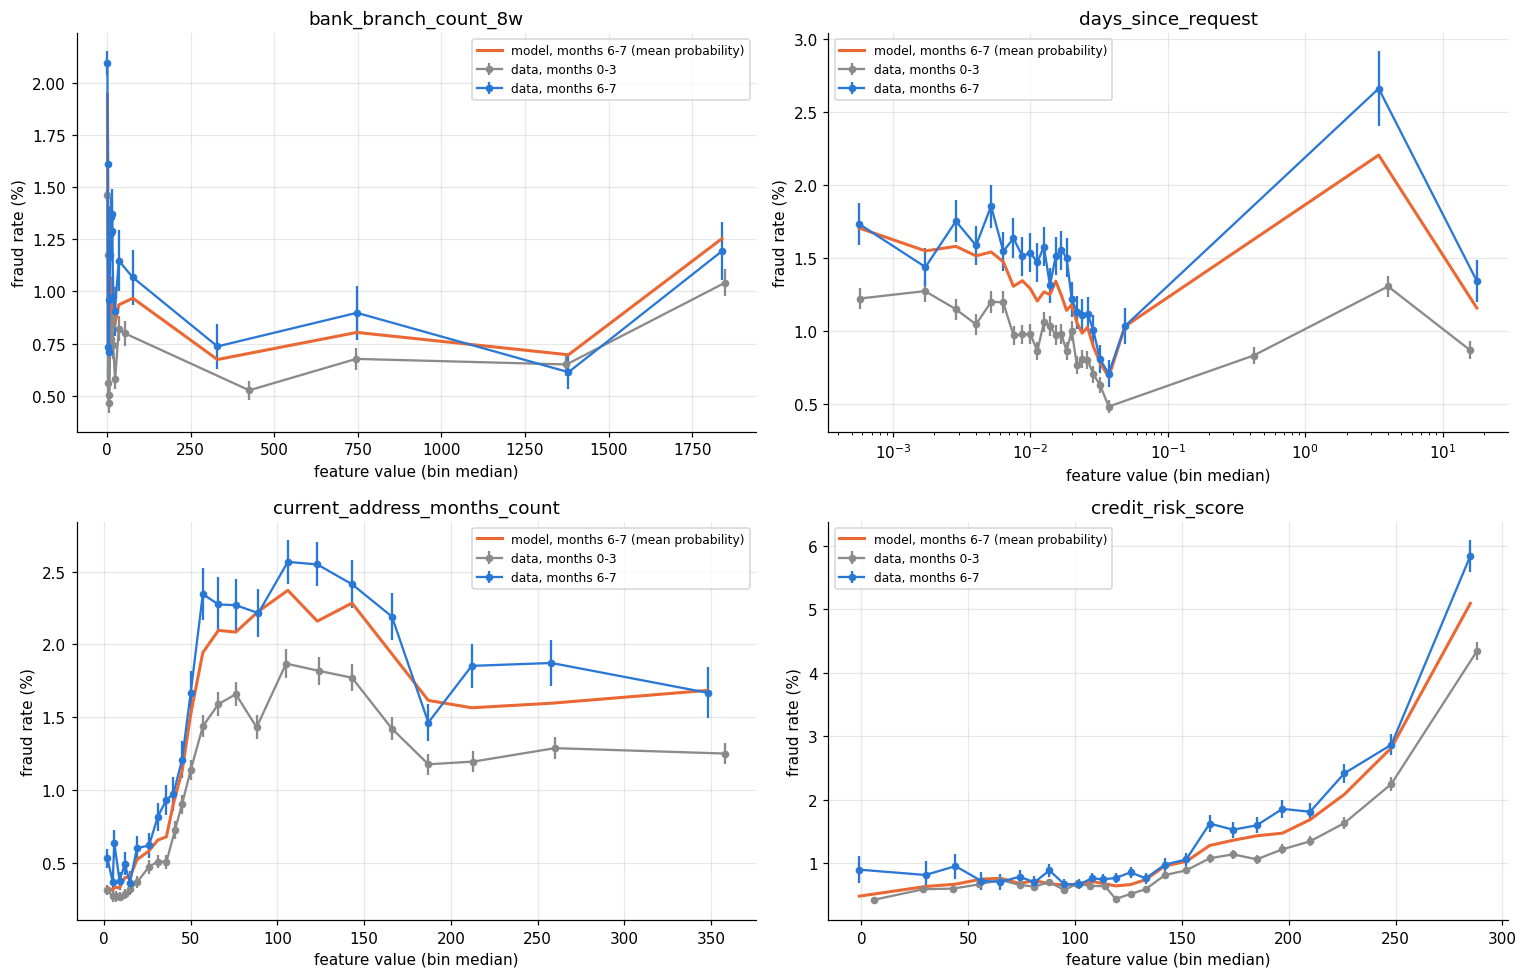

,bins,months 0-3 vs 6-7 (data),data 6-7 vs model
feature,,,
bank_branch_count_8w,19,0.904,0.902
days_since_request,25,0.805,0.885
current_address_months_count,25,0.966,0.958
credit_risk_score,25,0.705,0.682


In [24]:
SHAPE_FEATURES = ['bank_branch_count_8w', 'days_since_request', 'current_address_months_count', 'credit_risk_score']


def binned_rates(values, y, edges, probability=None):
    """Fraud rate (and the model's mean probability) per bin."""
    frame = pd.DataFrame({'v': values, 'y': y})
    named = {'n': ('y', 'size'), 'rate': ('y', 'mean'), 'x': ('v', 'median')}
    if probability is not None:
        frame['p'] = probability
        named['model'] = ('p', 'mean')
    frame = frame.dropna(subset=['v'])
    key = pd.cut(frame['v'], edges, include_lowest=True).rename('bin')
    out = frame.groupby(key, observed=True).agg(**named)
    out['se'] = np.sqrt(out['rate'] * (1 - out['rate']) / out['n'])
    return out


fig, axes = plt.subplots(2, 2, figsize=(14, 9))
rows = []
for ax, group in zip(axes.flatten(), SHAPE_FEATURES):
    train_values = X_train[group].to_numpy(dtype=float)
    test_values = X_test[group].to_numpy(dtype=float)
    pooled = np.concatenate([train_values[~np.isnan(train_values)], test_values[~np.isnan(test_values)]])
    edges = np.unique(np.quantile(pooled, np.linspace(0, 1, 26)))
    early = binned_rates(train_values, y_train, edges)
    late = binned_rates(test_values, y_test, edges, calibrated_test)

    ax.errorbar(early['x'], early['rate'] * 100, yerr=early['se'] * 100, fmt='o-', color=GREY, markersize=4,
                label='data, months 0-3')
    ax.errorbar(late['x'], late['rate'] * 100, yerr=late['se'] * 100, fmt='o-', color=BLUE, markersize=4,
                label='data, months 6-7')
    ax.plot(late['x'], late['model'] * 100, color=ORANGE, linewidth=2, label='model, months 6-7 (mean probability)')
    if pooled.min() > 0 and np.percentile(pooled, 99) / np.percentile(pooled, 1) > 100:
        ax.set_xscale('log')
    ax.set_title(group)
    ax.set_xlabel('feature value (bin median)')
    ax.set_ylabel('fraud rate (%)')
    ax.legend(fontsize=8)

    both = pd.concat({'early': early['rate'], 'late': late['rate'], 'model': late['model']}, axis=1).dropna()
    rows.append({'feature': group, 'bins': len(both),
                 'months 0-3 vs 6-7 (data)': both['early'].corr(both['late'], method='spearman'),
                 'data 6-7 vs model': both['late'].corr(both['model'], method='spearman')})
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index('feature').round(3)

### **7.5 Categorical Features, Category by Category**
- The beeswarm colours a category by its position in the category list, which means nothing. Here each category gets its own average contribution (the bar) and the spread of its contributions (whiskers, caused by interactions with other features). The label under each bar is that category's **fraud rate on months 0-3** (the EDA numbers), so the bars can be compared with the data directly. Categories with fewer than 1,000 test applications are unreliable.

**Results**
- Contributions follow the fraud rates. BA housing +0.82 (fraud 3.35% in months 0–3, 4.5% in months 6–7) and windows +0.65 (2.2%) push towards fraud. Linux −0.66 (0.4%), CF employment −0.97 (0.18%) and BE housing −0.61 (0.33%) push away.
- payment_type and source barely matter (average contributions near zero, for example INTERNET +0.0001).
- Fraud rose in months 6–7 for almost every category (BA 3.35% → 4.5%, windows 2.2% → 3.2%).
- Ignore the tiny categories: payment_type AE (41 rows), employment CG (81), housing BF (311) and BG (30) have fewer than 1,000 test rows.
- Wide whiskers for some categories (CF employment std 0.11) mean the effect depends on other features.
- Employment codes are separated by direction. The largest group, CA (77% of test applications), pushes slightly towards fraud (+0.12), as does the small CC (+0.13), while CB, CD, CE and CF push away (-0.47, -0.37, -0.66 and -0.97). The model therefore treats the employment codes as a spread from risky to safe and not as one effect. Because the codes are anonymised, no business reason can be given.

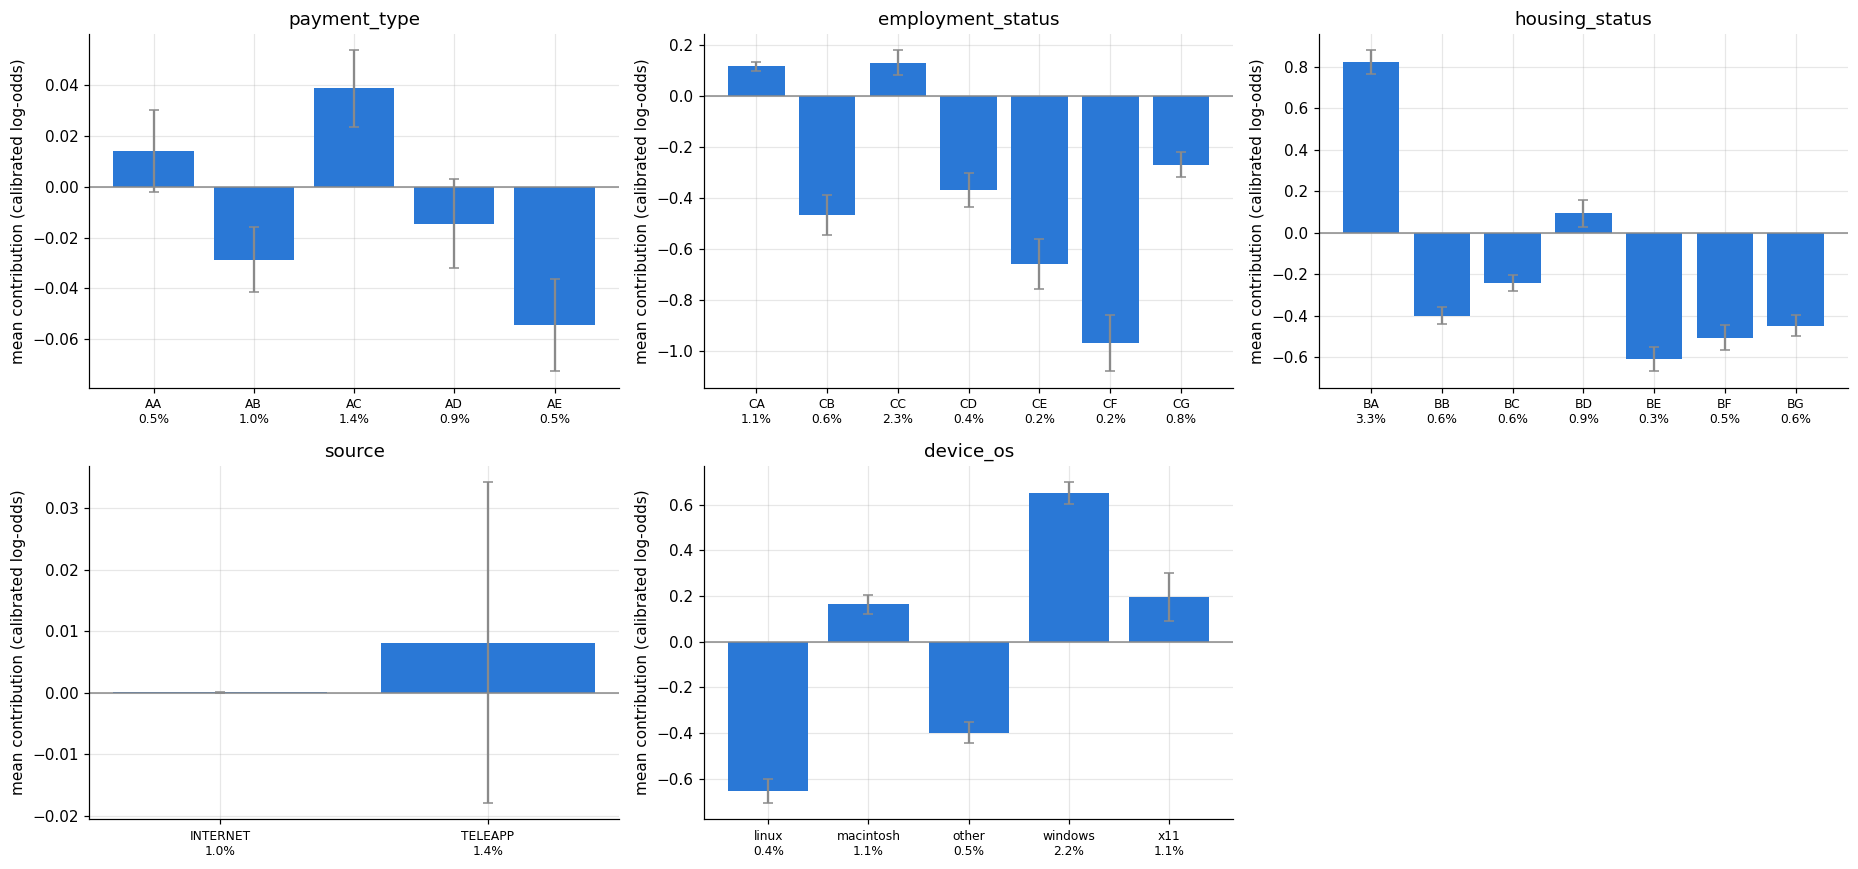

test rows  share of test rows  \
feature           category                                   
payment_type      AA             49329              0.2406   
                  AB             82372              0.4018   
                  AC             53492              0.2609   
                  AD             19777              0.0965   
                  AE                41              0.0002   
employment_status CA            158709              0.7741   
                  CB             22838              0.1114   
                  CC              6511              0.0318   
                  CD              4517              0.0220   
                  CE              4550              0.0222   
                  CF              7805              0.0381   
                  CG                81              0.0004   
housing_status    BA             39900              0.1946   
                  BB             56375              0.2750   
                  BC             70264              0.3427   
                  BD              8205              0.0400   
                  BE             29926              0.1460   
                  BF               311              0.0015   
                  BG                30              0.0001   
source            INTERNET      203700              0.9936   
                  TELEAPP         1311              0.0064   
device_os         linux          65032              0.3172   
                  macintosh      10815              0.0528   
                  other          77301              0.3771   
                  windows        50581              0.2467   
                  x11             1282              0.0063   

                             fraud rate months 0-3  fraud rate months 6-7  \
feature           category                                                  
payment_type      AA                        0.0052                 0.0064   
                  AB                        0.0101                 0.0142   
                  AC                        0.0145                 0.0201   
                  AD                        0.0090                 0.0159   
                  AE                        0.0051                 0.0000   
employment_status CA                        0.0107                 0.0152   
                  CB                        0.0060                 0.0095   
                  CC                        0.0229                 0.0310   
                  CD                        0.0044                 0.0029   
                  CE                        0.0024                 0.0033   
                  CF                        0.0018                 0.0022   
                  CG                        0.0080                 0.0247   
housing_status    BA                        0.0335                 0.0448   
                  BB                        0.0057                 0.0069   
                  BC                        0.0058                 0.0070   
                  BD                        0.0090                 0.0085   
                  BE                        0.0033                 0.0046   
                  BF                        0.0051                 0.0032   
                  BG                        0.0057                 0.0000   
source            INTERNET                  0.0096                 0.0140   
                  TELEAPP                   0.0140                 0.0244   
device_os         linux                     0.0044                 0.0074   
                  macintosh                 0.0112                 0.0192   
                  other                     0.0053                 0.0073   
                  windows                   0.0219                 0.0317   
                  x11                       0.0106                 0.0148   

                             mean contribution  std of contribution  
feature           category                                       

In [25]:
rows = []
for group in CATEGORICAL_GROUPS:
    c = grouped_shap[0][:, GROUP_NAMES.index(group)] * A[0]
    frame = pd.DataFrame({'category': X_test[group].astype(object).to_numpy(), 'contribution': c, 'fraud': y_test})
    train_rate = pd.Series(y_train).groupby(X_train[group].astype(object).to_numpy()).mean()
    for level, part in frame.groupby('category'):
        rows.append({'feature': group, 'category': level, 'test rows': len(part),
                     'share of test rows': len(part) / len(frame),
                     'fraud rate months 0-3': train_rate.get(level, np.nan),
                     'fraud rate months 6-7': part['fraud'].mean(),
                     'mean contribution': part['contribution'].mean(),
                     'std of contribution': part['contribution'].std()})
category_table = pd.DataFrame(rows).set_index(['feature', 'category'])

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, group in zip(axes.flatten(), CATEGORICAL_GROUPS):
    part = category_table.loc[group]
    positions = np.arange(len(part))
    ax.bar(positions, part['mean contribution'], yerr=part['std of contribution'], color=BLUE, ecolor=GREY, capsize=3)
    ax.axhline(0, color=GREY, linewidth=1)
    ax.set_xticks(positions)
    ax.set_xticklabels([f'{level}\n{rate:.1%}' for level, rate in zip(part.index, part['fraud rate months 0-3'])],
                       fontsize=8)
    ax.set_title(group)
    ax.set_ylabel('mean contribution (calibrated log-odds)')
for ax in axes.flatten()[len(CATEGORICAL_GROUPS):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()
category_table.round(4)

## **8. Surrogate Tree**
- A small decision tree is trained to imitate the XGBoost score (seed 0), so its rules can be read as plain if-then statements. It is fitted on month 5 (not used for training the model) and judged on months 6-7. Categories are one-hot encoded and missing values are set to -1 for the tree (the `_missing` flags are there to read).
- How faithful it is:
    - **R2 on the margin**: how much of the variation of the model's log-odds the tree reproduces,
    - **Spearman correlation** with the model's scores: whether it ranks applications the same way,
    - **recall at 5% FPR** on the real labels, next to the model's own: whether the rules alone would be a usable detector. A tree with few leaves has few distinct scores, so this number is coarse.
- **Depth 4 (16 leaves) is used.** Each extra level adds less fidelity (R2 gains of 0.12, 0.10, 0.07, 0.05, 0.03 from depth 3 to 7) while doubling the number of rules, and 16 rules can be read on one page.
- A rule's probability is the Platt-calibrated value of the average margin in that leaf, so it is approximate. For a column with a `_missing` flag, a rule `<= x` also includes the applications where the value is missing (set to -1); the printout says so.
- Depths 2-7 tabulated, at least 200 applications per leaf (about 0.2% of month 5), depth 4 (16 leaves) printed: The table shows how fidelity grows with depth. 200 per leaf keeps each rule's probability from resting on a handful of cases. Depth 4 is the largest tree whose rules fit on one screen. Its fidelity is moderate (R-squared 0.54), so it is a story about the model, not a replacement.

**Results**
- The rules use the same features as the importance rankings. The top split is housing BA, then device OS Windows, has_other_cards, phone_home_valid and prev_address_months_count. The 16 leaves give probabilities from 0.03% to 8.8% (BA + Windows + no other cards + invalid phone).
- Fidelity is limited. The depth-4 tree reproduces R2 = 0.54 of the model's margin, Spearman 0.70, and recall at 5% FPR of 0.338 against 0.55 for XGBoost. Even at depth 7 (103 leaves) R2 is only 0.69 and recall 0.41.
- The rules are a readable summary, not a substitute. The model's logic is spread over many features and interactions, which a small tree cannot capture.
- The recall column is not monotonic in depth (0.338 at depths 3 and 4, 0.282 at depth 5, 0.410 at depth 7; 0.000 at depth 2), because a tree with few leaves has few distinct scores, so the threshold cannot be set precisely. Use R2 and Spearman to judge fidelity.

In [26]:
categorical_columns = list(CATEGORY_LEVELS)


def surrogate_inputs(X):
    return pd.get_dummies(X, columns=categorical_columns, dtype=float).fillna(-1)


S_fit = surrogate_inputs(X_month5)
S_test = surrogate_inputs(X_test)[S_fit.columns]
margin_month5 = contributions(models[0], X_month5)[2]
margin_test = shap_values[0].sum(axis=1) + base_values[0]    # the contributions add up to the margin (section 2.1)

model_recall = recall_at_fpr(y_test, score0)
rows = []
for depth in range(2, 8):
    tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=200, random_state=0).fit(S_fit, margin_month5)
    predicted = tree.predict(S_test)
    rows.append({'depth': depth, 'leaves': tree.get_n_leaves(),
                 'R2 on margin (months 6-7)': r2_score(margin_test, predicted),
                 'Spearman with XGBoost': pd.Series(predicted).corr(pd.Series(margin_test), method='spearman'),
                 'recall@5%FPR (labels)': recall_at_fpr(y_test, predicted),
                 'XGBoost recall@5%FPR': model_recall})
surrogate_table = pd.DataFrame(rows).set_index('depth')
surrogate_table.round(3)

,leaves,R2 on margin (months 6-7),Spearman with XGBoost,recall@5%FPR (labels),XGBoost recall@5%FPR
depth,,,,,
2,4,0.317,0.539,0.000,0.55
3,8,0.439,0.632,0.338,0.55
4,16,0.535,0.700,0.338,0.55
5,32,0.603,0.758,0.282,0.55
6,59,0.651,0.791,0.386,0.55
7,103,0.686,0.814,0.410,0.55


In [27]:
SURROGATE_DEPTH = 4


def print_rules(tree, names, a, b, node=0, depth=0):
    t = tree.tree_
    indent = '|   ' * depth
    if t.children_left[node] == -1:
        probability = sigmoid(a * t.value[node][0][0] + b)
        print(f'{indent}-> fraud probability about {probability:.4f}   ({t.n_node_samples[node]:,} applications on month 5)')
        return
    name = names[t.feature[node]]
    note = '  (includes missing)' if f'{name}_missing' in names and t.threshold[node] > -1 else ''
    print(f'{indent}if {name} <= {t.threshold[node]:.3g}:{note}')
    print_rules(tree, names, a, b, t.children_left[node], depth + 1)
    print(f'{indent}else ({name} > {t.threshold[node]:.3g}):')
    print_rules(tree, names, a, b, t.children_right[node], depth + 1)


surrogate = DecisionTreeRegressor(max_depth=SURROGATE_DEPTH, min_samples_leaf=200, random_state=0).fit(S_fit, margin_month5)
print_rules(surrogate, list(S_fit.columns), A[0], B[0])

if housing_status_BA <= 0.5:
|   if device_os_windows <= 0.5:
|   |   if prev_address_months_count <= 6.5:  (includes missing)
|   |   |   if has_other_cards <= 0.5:
|   |   |   |   -> fraud probability about 0.0029   (43,368 applications on month 5)
|   |   |   else (has_other_cards > 0.5):
|   |   |   |   -> fraud probability about 0.0009   (17,859 applications on month 5)
|   |   else (prev_address_months_count > 6.5):
|   |   |   if phone_home_valid <= 0.5:
|   |   |   |   -> fraud probability about 0.0009   (8,404 applications on month 5)
|   |   |   else (phone_home_valid > 0.5):
|   |   |   |   -> fraud probability about 0.0003   (6,121 applications on month 5)
|   else (device_os_windows > 0.5):
|   |   if has_other_cards <= 0.5:
|   |   |   if prev_address_months_count <= 7.5:  (includes missing)
|   |   |   |   -> fraud probability about 0.0093   (14,698 applications on month 5)
|   |   |   else (prev_address_months_count > 7.5):
|   |   |   |   -> fraud probability about 0.0

## **9. Reason Codes: 4 Example Cases**
For one application, the **reason codes** are a list of features with the largest contributions to that application's score, shown with the application's value for each features, and a plain-language wording. It shows how the model’s decisions can be explained to a fraud analyst case by case. It also exposes how the model fails. The false positive is flagged for the same kinds of reasons as the true positive, so an analyst can see why a genuine applicant was caught.

1. Picks four example applications at random from the test months, one per outcome: a flagged fraud (true positive), a flagged genuine one (false positive), a missed fraud (false negative) and a correct pass (true negative).
2. For each, starts at the calibrated baseline (1.2%), adds the contributions, and converts the total into a calibrated fraud probability.
3. Lists the top five reasons with direction (towards fraud or towards genuine). Wording like “device operating system is windows” replaces device_os = windows. Numeric ranges in the wording come from the dependence plots, so they must be re-checked if the model changes.
4. Checks that baseline plus all contributions equals the application’s calibrated log-odds exactly (differences of 2e-7 to 2.4e-6).
5. Prints the flagging threshold in two units: raw score 0.475, which equals a calibrated fraud probability of 0.044. A flagged application needs a probability above 0.044.

**Example (true positive)**: Calibrated probability 0.47, against a baseline of 0.012. The main reasons are BA housing (+0.79), Windows (+0.68), a high credit risk score of 285 (+0.58), income band 0.9 (+0.51) and 3 distinct emails (+0.35).

**Results**
- The threshold has a meaning. Raw score 0.475 equals a calibrated fraud probability of 0.044. Flagging at that probability is the right rule when a missed fraud costs about 22 false alarms.
- Reason codes are exact. The baseline plus all contributions reproduces the calibrated log-odds to within 3e-6.
- The true positive (probability 0.47) is explained by BA housing, Windows, a high credit risk score (285), income band 0.9 and 3 distinct emails.
- The false positive (0.15) looks like fraud on the same features (Windows, risk score 253, income 0.9, an email unlike the name), so the model can’t tell it from fraud, and the reasons make that clear to an analyst.
- The false negative (0.029, below the 0.044 threshold) has the same fraud-pushing features as the true positive, but a valid home phone (−0.67) pulls it under the threshold. 
- The false positive's reasons include `days_since_request` (0.0378 days), which pulls it towards genuine by -0.44. This is the feature whose timing is doubtful in section 14, so it matters that the model uses it on individual decisions.
- The true negative (0.003) shows a rare large effect: 2 distinct emails on the device push it towards fraud by +1.08, but many small genuine-pointing reasons keep the total low.

In [28]:
thresholds = {int(seed): t for seed, t in final_model['thresholds'].items()}
flagged = score0 >= thresholds[0]


def display_value(group, i, X=None):
    X = X_test if X is None else X
    value = X[group].iloc[i]
    if pd.isna(value):
        return 'missing'
    return f'{value:.3g}' if isinstance(value, (float, np.floating)) else str(value)


BINARY_PHRASES = {
    'phone_home_valid': {1: 'home phone number is valid', 0: 'home phone number is not valid'},
    'phone_mobile_valid': {1: 'mobile phone number is valid', 0: 'mobile phone number is not valid'},
    'has_other_cards': {1: 'has other cards with the bank', 0: 'has no other cards with the bank'},
    'keep_alive_session': {1: 'chose to stay logged in (keep-alive)', 0: 'did not choose keep-alive'},
    'email_is_free': {1: 'email is from a free domain', 0: 'email is not from a free domain'},
    'foreign_request': {1: 'request from outside the bank country', 0: 'request from the bank country'},
}
CATEGORY_PHRASES = {
    'device_os': 'device operating system is {}',
    'housing_status': 'housing status {}',
    'employment_status': 'employment status {}',
    'payment_type': 'payment plan type {}',
    'source': 'application source is {}',
}


def plain_language(group, value):
    """A plain-language phrase for one value. The ranges for numeric features are read off the section 7.3 plots."""
    missing = pd.isna(value)
    if group in BINARY_PHRASES and not missing:
        return BINARY_PHRASES[group].get(int(value))
    if group in CATEGORY_PHRASES and not missing:
        return CATEGORY_PHRASES[group].format(value)
    if group == 'prev_address_months_count':
        return 'no previous address on record' if missing else f'previous address on record ({value:.0f} months)'
    if group == 'current_address_months_count':
        if missing:
            return 'time at current address unknown'
        if value < 40:
            return f'{value:.0f} months at current address (under 40)'
        return (f'{value:.0f} months at current address (40 to 150)' if value < 150
                else f'{value:.0f} months at current address (over 150)')
    if group == 'name_email_similarity' and not missing:
        if value < 0.2:
            return f'email very different from the name ({value:.2f})'
        return (f'email moderately similar to the name ({value:.2f})' if value < 0.8
                else f'email very similar to the name ({value:.2f})')
    if group == 'income' and not missing:
        return f'income band {value:.1f} (on a scale from 0.1 to 0.9)'
    if group == 'customer_age' and not missing:
        return f'applicant aged in their {int(value)}s'
    if group == 'credit_risk_score' and not missing:
        return f'high credit risk score ({value:.0f})' if value >= 230 else f'credit risk score {value:.0f}'
    if group == 'bank_months_count':
        return 'no previous bank account on record' if missing else f'previous bank account {value:.0f} months old'
    if group == 'intended_balcon_amount':
        return 'no initial transfer amount' if missing else f'initial transfer amount {value:.1f}'
    if group == 'device_distinct_emails_8w' and not missing:
        return f'{value:.0f} distinct emails seen on this device in 8 weeks'
    if group == 'date_of_birth_distinct_emails_4w' and not missing:
        return f'{value:.0f} distinct emails for applicants with this date of birth (4 weeks)'
    if group == 'bank_branch_count_8w' and not missing:
        return f'{value:.0f} applications at this bank branch in 8 weeks'
    if group == 'proposed_credit_limit' and not missing:
        return f'proposed credit limit {value:.0f}'
    if group == 'days_since_request' and not missing:
        return f'{value:.3g} days since the application was made'
    if group == 'session_length_in_minutes':
        return 'session length unknown' if missing else f'session length {value:.1f} minutes'
    return None


def reason_codes(i, seed=0, top=5, X=None, contributions_array=None):
    """The largest contributions to one application's calibrated log-odds (a value and its flag together).
    By default for application i of the Base test months; for other data pass its features X and its
    contributions (already in calibrated log-odds, one column per group)."""
    X = X_test if X is None else X
    contribution = grouped_shap[seed][i] * A[seed] if contributions_array is None else contributions_array[i]
    order = np.argsort(-np.abs(contribution))[:top]
    groups_i = [GROUP_NAMES[j] for j in order]
    shown = [display_value(g, i, X) for g in groups_i]
    return pd.DataFrame({
        'reason': [plain_language(g, X[g].iloc[i]) or f'{g} = {v}' for g, v in zip(groups_i, shown)],
        'feature': groups_i,
        'value': shown,
        'effect (calibrated log-odds)': contribution[order],
        'direction': np.where(contribution[order] > 0, 'towards fraud', 'towards genuine'),
    })


case_rng = np.random.default_rng(7)


def pick(mask):
    candidates = np.flatnonzero(mask)
    return int(case_rng.choice(candidates)) if len(candidates) else None


cases = {
    'true positive (fraud, flagged)': pick(flagged & (y_test == 1)),
    'false positive (genuine, flagged)': pick(flagged & (y_test == 0)),
    'false negative (fraud, not flagged)': pick(~flagged & (y_test == 1)),
    'true negative (genuine, not flagged)': pick(~flagged & (y_test == 0)),
}
cases = {name: i for name, i in cases.items() if i is not None}   # skip an outcome that has no example

baseline_log_odds = A[0] * base_values[0] + B[0]
threshold_probability = float(calibrate(np.array([thresholds[0]]), seed=0)[0])
print(f'Frozen threshold (seed 0): raw score {thresholds[0]:.3f} = calibrated fraud probability {threshold_probability:.3f}. '
      f'Flagging at this probability is the Bayes rule for a missed fraud that costs {1 / threshold_probability - 1:.0f} false alarms.')
print()
for name, i in cases.items():
    total = (grouped_shap[0][i] * A[0]).sum()
    probability = sigmoid(baseline_log_odds + total)
    print(f'{name}: raw score {score0[i]:.3f}, calibrated fraud probability {probability:.3f} '
          f'(baseline {sigmoid(baseline_log_odds):.3f}), flagged: {"yes" if flagged[i] else "no"}')
    print(f'  check: baseline + all contributions vs calibrated log-odds, difference '
          f'{abs(baseline_log_odds + total - (A[0] * np.log(score0[i] / (1 - score0[i])) + B[0])):.1e}')
    print(reason_codes(i).round(3).to_string(index=False))
    print()

Frozen threshold (seed 0): raw score 0.475 = calibrated fraud probability 0.044. Flagging at this probability is the Bayes rule for a missed fraud that costs 22 false alarms.

true positive (fraud, flagged): raw score 0.939, calibrated fraud probability 0.470 (baseline 0.012), flagged: yes
  check: baseline + all contributions vs calibrated log-odds, difference 7.2e-07
                                                            reason                          feature   value  effect (calibrated log-odds)     direction
                                                 housing status BA                   housing_status      BA                         0.793 towards fraud
                                device operating system is windows                        device_os windows                         0.684 towards fraud
                                      high credit risk score (285)                credit_risk_score     285                         0.579 towards fraud
                    

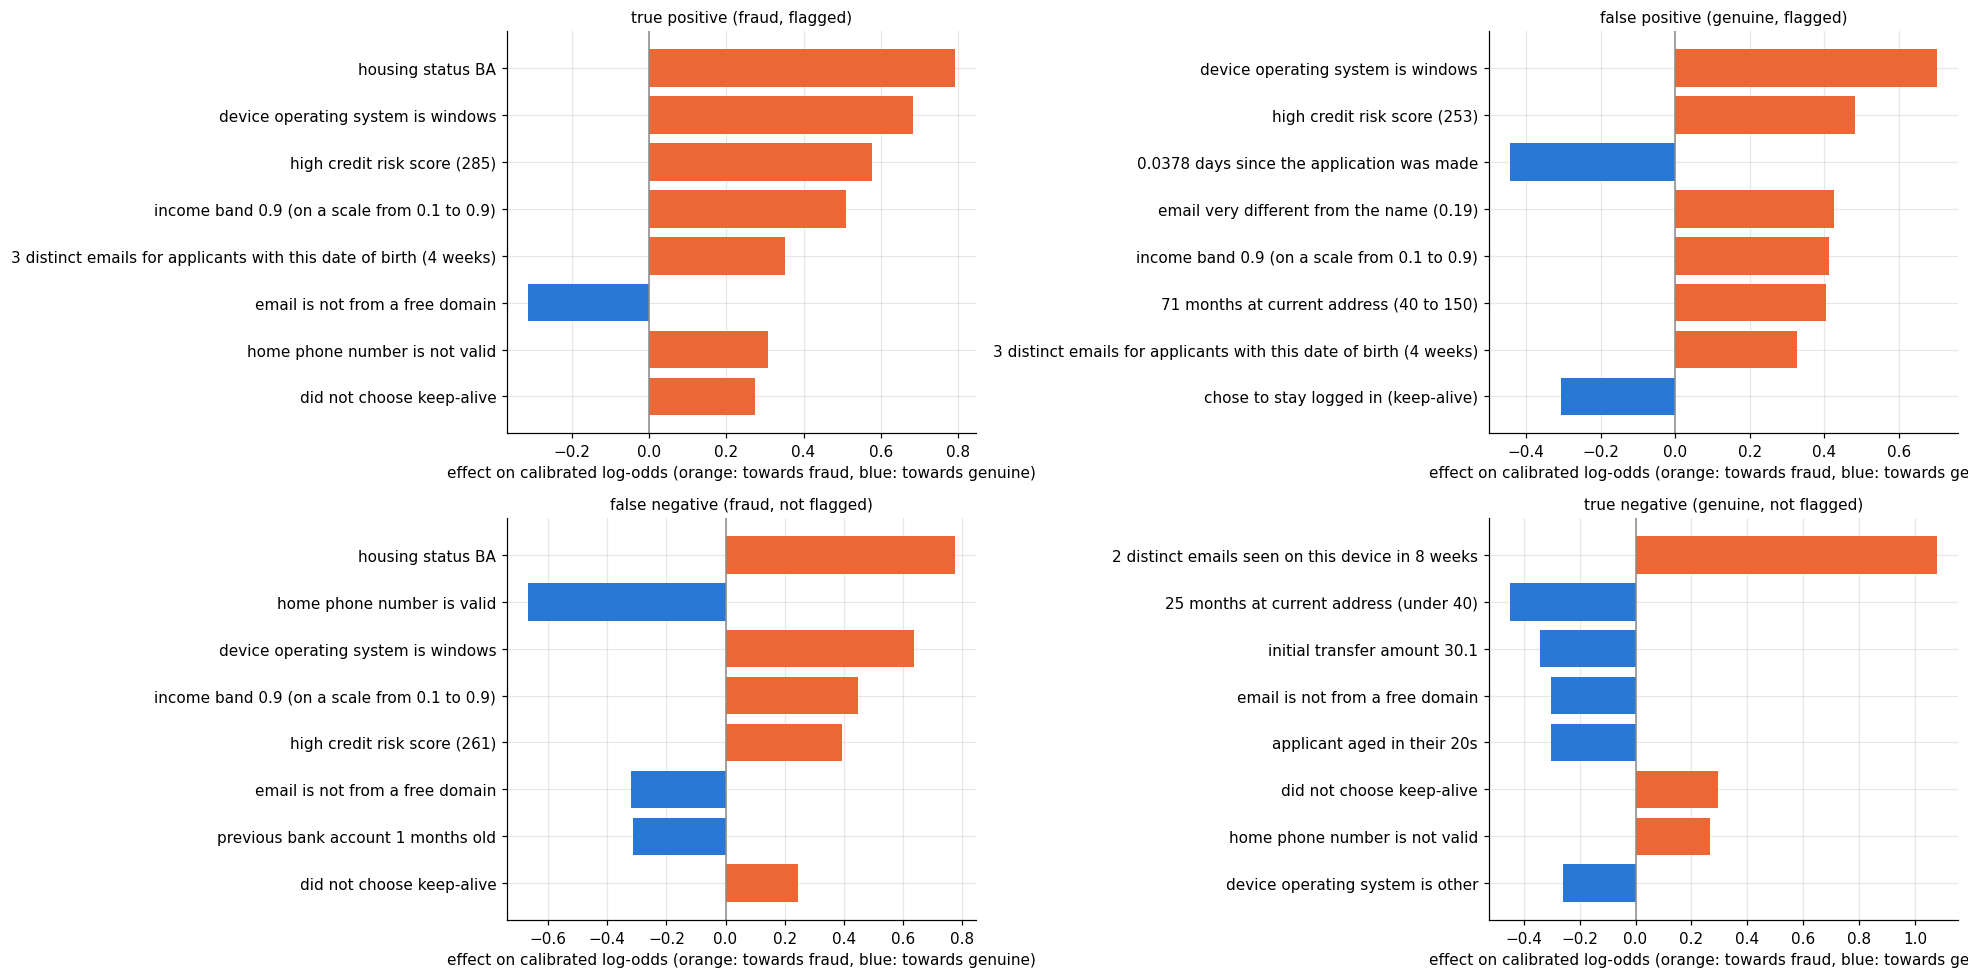

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(18, 9))
for ax, (name, i) in zip(axes.flatten(), cases.items()):
    codes = reason_codes(i, top=8).iloc[::-1]
    labels = list(codes['reason'])
    colours = [ORANGE if effect > 0 else BLUE for effect in codes['effect (calibrated log-odds)']]
    ax.barh(labels, codes['effect (calibrated log-odds)'], color=colours)
    ax.axvline(0, color=GREY, linewidth=1)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('effect on calibrated log-odds (orange: towards fraud, blue: towards genuine)')
plt.tight_layout()
plt.show()

### **9.1 The Threshold, in Cost Terms**
**Purpose.** State the frozen threshold as a business rule: what cost ratio does it assume?

**Method.** With calibrated probabilities (section 2.3), flagging at probability p is the best rule (the Bayes rule; notebook 04, sections 9-10) when a missed fraud costs (1 - p) / p false alarms. So the frozen threshold implies a cost ratio. The second table goes the other way: for a cost ratio R, flag at probability 1 / (1 + R). The ratios 5, 10, 20 and 50 are notebook 03's grid. The calibration levels drift by month (section 11), so these ratios are approximate.

**Results**
- **The frozen threshold stands for a calibrated probability of 4.4%** in every seed (raw score 0.474-0.477), which implies a missed fraud costing about **21.5-21.7 false alarms**, consistent with notebook 04's "about 20".
- | R | flag if probability ≥ | share flagged | recall | FPR |
  |---|---|---|---|---|
  | 5 | 0.167 | 1.2% | 0.232 | 0.8% |
  | 10 | 0.091 | 2.7% | 0.389 | 2.2% |
  | 20 | 0.048 | 5.6% | 0.544 | 4.9% |
  | 50 | 0.020 | 12.8% | 0.726 | 11.9% |
- **The frozen threshold corresponds to R = 20,** with 5% of genuine applicants flagged.

In [30]:
rows = []
for seed in SEEDS:
    probability = float(calibrate(np.array([thresholds[seed]]), seed=seed)[0])
    rows.append({'seed': seed, 'raw score threshold': thresholds[seed], 'calibrated probability at threshold': probability,
                 'implied cost ratio (false alarms per missed fraud)': 1 / probability - 1})
threshold_rationale = pd.DataFrame(rows).set_index('seed')
print(threshold_rationale.round(3).to_string())
print()

rows = []
for ratio in [5, 10, 20, 50]:
    cut = 1 / (1 + ratio)
    flagged_here = calibrated_test >= cut
    rows.append({'cost ratio R': ratio, 'flag if calibrated probability >=': cut, 'share of applications flagged': flagged_here.mean(),
                 'recall': flagged_here[y_test == 1].mean(), 'FPR': flagged_here[genuine].mean()})
pd.DataFrame(rows).set_index('cost ratio R').round(3)

      raw score threshold  calibrated probability at threshold  implied cost ratio (false alarms per missed fraud)
seed                                                                                                              
0                   0.475                                0.044                                              21.586
1                   0.474                                0.044                                              21.708
2                   0.477                                0.044                                              21.483
3                   0.477                                0.044                                              21.555
4                   0.474                                0.044                                              21.707



,flag if calibrated probability >=,share of applications flagged,recall,FPR
cost ratio R,,,,
5,0.167,0.012,0.232,0.008
10,0.091,0.027,0.389,0.022
20,0.048,0.056,0.544,0.049
50,0.020,0.128,0.726,0.119


**Example:** One flagged fraud case from section 9, from reasons to decision: the reason codes add up (with the baseline) to a calibrated probability, and the decision compares that probability with the one the threshold stands for.

In [31]:
case_name = 'true positive (fraud, flagged)'
if case_name in cases:
    i = cases[case_name]
    probability = sigmoid(baseline_log_odds + (grouped_shap[0][i] * A[0]).sum())
    print(f'{case_name}: application {i} of the test months')
    print(reason_codes(i).round(3).to_string(index=False))
    print()
    print(f'Baseline fraud probability {sigmoid(baseline_log_odds):.1%}; the contributions above (and the rest) move it to '
          f'{probability:.1%}.')
    print(f'The frozen threshold stands for a probability of {threshold_probability:.1%}, which is a missed fraud costing '
          f'{1 / threshold_probability - 1:.0f} false alarms. {probability:.1%} is '
          f'{"above" if probability >= threshold_probability else "below"} it, so the application is '
          f'{"flagged" if flagged[i] else "not flagged"}.')
else:
    print('No true positive among the section 9 cases for this random draw.')

true positive (fraud, flagged): application 98144 of the test months
                                                            reason                          feature   value  effect (calibrated log-odds)     direction
                                                 housing status BA                   housing_status      BA                         0.793 towards fraud
                                device operating system is windows                        device_os windows                         0.684 towards fraud
                                      high credit risk score (285)                credit_risk_score     285                         0.579 towards fraud
                      income band 0.9 (on a scale from 0.1 to 0.9)                           income     0.9                         0.511 towards fraud
3 distinct emails for applicants with this date of birth (4 weeks) date_of_birth_distinct_emails_4w       3                         0.351 towards fraud

Baseline fraud pro

## **10. Stability of the Explanations**
Do the 5 frozen models (trained with different random seeds) **agree** on what matters (10.1), and do **similar applications** get similar explanations (10.2)?

### **10.1 Across Seeds, with Bootstrap Intervals**
Previous sections showed that the 5 seeds rank the features alike (lowest Spearman correlation 0.994 on the features, 0.991 on the groups). That is one number from one set of test applications. A different month would give slightly different numbers, so here the same question is asked with **bootstrap intervals**, in the way notebook 04 (section 5) did for the performance metrics:
1. Every test application gets a random weight (how many times it was drawn) from a Poisson distribution with mean 1, which is the standard large-sample version of resampling with replacement. 1,000 such resamples are made, with random seed 4012: the same size and seed as notebook 04. Every seed's model sees the same resampled applications.
2. For each resample and each seed, the importance of every group is the weighted mean |contribution|.
3. For each resample: the mean pairwise Spearman correlation between the seeds' importance rankings, the seed-averaged importance and share of every group, and its rank.
4. The interval is the range between the 2.5th and 97.5th percentiles over the resamples.

There are 2 sources of uncertainty: from other test applications, which the bootstrap answers, and other seeds, which the other training seeds answers.

**Results**
- The seeds agree. Mean pairwise Spearman between seeds is 0.995, with a 95% interval of 0.995 to 0.996.
- The ranks do not move. For the top 15 groups, the rank interval is a single value (device_os is rank 1 to 1, housing_status 2 to 2, and so on). Share intervals are also narrow (device_os 0.0981 to 0.0983). So the ordering of the top groups is a stable fact.
- The interval is narrow because it measures only sampling noise within months 6–7. The next table shows the real month-to-month movement, so use that when you talk about stability over time.
- Share moves much more between months than the bootstrap suggests. Between month 6 and 7, prev_address_months_count goes from 0.0667 to 0.0789 (+0.012) and has_other_cards from 0.0658 to 0.0580 (−0.008), against bootstrap widths of about 0.0005. Section 11 follows this up across all months.

1,000 resamples x 5 seeds in 9 s
Mean pairwise Spearman correlation between the seeds' grouped rankings: 0.995 on the real test set, 95% interval over resamples 0.995 to 0.996


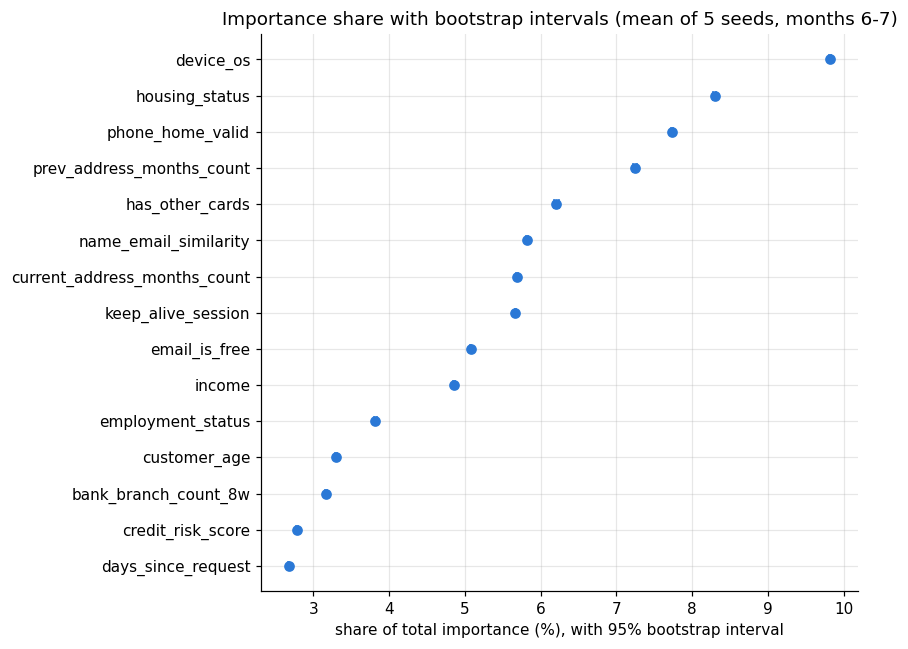

,importance (real test set),share (real test set),"share, 2.5%","share, 97.5%",rank (real test set),"rank, 2.5%","rank, 97.5%"
device_os,0.5286,0.0982,0.0981,0.0983,1,1,1
housing_status,0.4467,0.0830,0.0828,0.0832,2,2,2
phone_home_valid,0.4162,0.0773,0.0772,0.0774,3,3,3
prev_address_months_count,0.3902,0.0725,0.0722,0.0727,4,4,4
has_other_cards,0.3343,0.0621,0.0618,0.0624,5,5,5
name_email_similarity,0.3131,0.0582,0.0580,0.0583,6,6,6
current_address_months_count,0.3062,0.0569,0.0568,0.0570,7,7,7
keep_alive_session,0.3051,0.0567,0.0566,0.0567,8,8,8
email_is_free,0.2735,0.0508,0.0507,0.0509,9,9,9
income,0.2614,0.0485,0.0484,0.0487,10,10,10


In [32]:
N_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 4012   # the same as notebook 04, section 5
BATCH = 10              # resamples handled together (limits memory use)

absolute_by_seed = {seed: (np.abs(grouped_shap[seed]) * A[seed]).astype(np.float32) for seed in SEEDS}
bootstrap_rng = np.random.default_rng(BOOTSTRAP_SEED)
draw_parts = {seed: [] for seed in SEEDS}
start = time.time()
for _ in range(N_BOOTSTRAP // BATCH):
    weights = bootstrap_rng.poisson(1.0, size=(BATCH, len(X_test))).astype(np.float32)
    totals = weights.sum(axis=1, keepdims=True)
    for seed in SEEDS:
        draw_parts[seed].append(weights @ absolute_by_seed[seed] / totals)
draws = {seed: np.vstack(parts) for seed, parts in draw_parts.items()}       # resamples x groups
print(f'{N_BOOTSTRAP:,} resamples x {len(SEEDS)} seeds in {time.time() - start:.0f} s')


def row_ranks(matrix):
    return matrix.argsort(axis=1).argsort(axis=1).astype(float)    # rank 0 = smallest, per resample


def mean_pairwise_spearman(rank_by_seed):
    centred = {seed: r - r.mean(axis=1, keepdims=True) for seed, r in rank_by_seed.items()}
    values = []
    for a_index, a_seed in enumerate(SEEDS):
        for b_seed in SEEDS[a_index + 1:]:
            numerator = (centred[a_seed] * centred[b_seed]).sum(axis=1)
            denominator = np.sqrt((centred[a_seed] ** 2).sum(axis=1) * (centred[b_seed] ** 2).sum(axis=1))
            values.append(numerator / denominator)
    return np.mean(values, axis=0)


seed_agreement = mean_pairwise_spearman({seed: row_ranks(draws[seed]) for seed in SEEDS})
real_agreement = grouped_correlation.to_numpy()[~np.eye(len(SEEDS), dtype=bool)].mean()
print(f'Mean pairwise Spearman correlation between the seeds\' grouped rankings: {real_agreement:.3f} on the real test set, '
      f'95% interval over resamples {np.quantile(seed_agreement, 0.025):.3f} to {np.quantile(seed_agreement, 0.975):.3f}')

average_draws = np.mean([draws[seed] for seed in SEEDS], axis=0)                  # resamples x groups
share_draws = average_draws / average_draws.sum(axis=1, keepdims=True)
rank_draws = (len(GROUP_NAMES) - row_ranks(average_draws)).astype(int)            # rank 1 = most important
stability = pd.DataFrame({
    'importance (real test set)': grouped_importance[MEAN].reindex(GROUP_NAMES),
    'share (real test set)': grouped_importance['share of total'].reindex(GROUP_NAMES),
    'share, 2.5%': np.quantile(share_draws, 0.025, axis=0),
    'share, 97.5%': np.quantile(share_draws, 0.975, axis=0),
    'rank (real test set)': grouped_importance[MEAN].reindex(GROUP_NAMES).rank(ascending=False).astype(int),
    'rank, 2.5%': np.quantile(rank_draws, 0.025, axis=0).astype(int),
    'rank, 97.5%': np.quantile(rank_draws, 0.975, axis=0).astype(int),
}, index=GROUP_NAMES).sort_values('rank (real test set)')

top15 = stability.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.errorbar(top15['share (real test set)'] * 100, range(len(top15)),
             xerr=[(top15['share (real test set)'] - top15['share, 2.5%']) * 100,
                   (top15['share, 97.5%'] - top15['share (real test set)']) * 100],
             fmt='o', color=BLUE, capsize=3)
plt.yticks(range(len(top15)), top15.index)
plt.xlabel('share of total importance (%), with 95% bootstrap interval')
plt.title('Importance share with bootstrap intervals (mean of 5 seeds, months 6-7)')
plt.tight_layout()
plt.show()
stability.head(15).round(4)

**The bootstrap interval is narrow, but it does not cover month-to-month change.** It resamples applications within months 6-7, so it only measures sampling noise. The next table shows the share of each group in month 6 and in month 7 separately (mean of the 5 seeds). The gap between the two months is a more honest picture of how much a share can move over time (section 11 covers all months).

In [33]:
month_values = test['month'].to_numpy()
share_by_month = {}
for month in TEST_MONTHS:
    in_month = month_values == month
    importance = np.mean([absolute_by_seed[seed][in_month].mean(axis=0) for seed in SEEDS], axis=0)
    share_by_month[f'share, month {month}'] = pd.Series(importance / importance.sum(), index=GROUP_NAMES)
month_table = pd.DataFrame(share_by_month)
month_table['difference between months'] = month_table.iloc[:, 1] - month_table.iloc[:, 0]
month_table['bootstrap interval width'] = stability['share, 97.5%'] - stability['share, 2.5%']
month_table.loc[stability.index[:15]].round(4)

,"share, month 6","share, month 7",difference between months,bootstrap interval width
device_os,0.0967,0.0999,0.0032,0.0002
housing_status,0.0856,0.0801,-0.0054,0.0004
phone_home_valid,0.0763,0.0785,0.0022,0.0002
prev_address_months_count,0.0667,0.0789,0.0123,0.0005
has_other_cards,0.0658,0.0580,-0.0079,0.0005
name_email_similarity,0.0576,0.0588,0.0012,0.0002
current_address_months_count,0.0552,0.0588,0.0036,0.0002
keep_alive_session,0.0564,0.0570,0.0006,0.0001
email_is_free,0.0515,0.0500,-0.0015,0.0001
income,0.0482,0.0489,0.0007,0.0002


### **10.2 Across Similar Applications**
A good explanation shouldn’t change wildly between two applications that look alike. For 500 random flagged applications, the 5 nearest neighbours are found in a pool of 50,000 (on standardised inputs), and the explanations of each pair are compared by two measures: rank correlation of the contribution vectors (1 = same ordering of which features matter), and top-3 overlap (the share of the 3 largest contributors that the two applications have in common).
- **Neighbours: a pool of 50,000 test applications, 500 flagged queries, 5 neighbours, standardised inputs.** The pool size keeps the nearest-neighbour search fast. 500 queries (2,500 pairs) give a stable average. 5 neighbours are close enough to be similar. The comparison with random flagged pairs and the seed-to-seed ceiling show whether the agreement is high or low.

The comparison baseline is a pair of **random flagged applications**. If neighbours score clearly higher than random pairs, the explanations are stable for similar cases. Three more views help to read the number:
- **neighbour also flagged or not**: a neighbour that is not flagged can have a legitimately different explanation, so the fair comparison is the flagged neighbours,
- **distance**: the closest quarter of neighbours should agree most,
- **a ceiling**: the same application explained by seed 0 and by seed 1 (a different but equally valid model). No pair of different applications can be expected to agree more than that.

**Results**
- Neighbours are much more alike than random pairs. Mean rank correlation is 0.579 for neighbours against 0.158 for random flagged pairs, and top-3 overlap is 0.661 against 0.487.
- Not as close as the ceiling. The same application explained by two seeds gives 0.989, so neighbours at 0.58 do not agree as closely as two equally valid models. The explanations are moderately stable, not identical.
- A flagged neighbour agrees more than an unflagged one (0.615 against 0.544), which is expected, since an unflagged neighbour can legitimately have a different explanation.
- Closer neighbours agree more. Rank correlation falls from 0.714 for the closest quarter to 0.420 for the farthest, so agreement depends on how similar the applications really are.
- A weak tail. The 10th percentile of neighbour pairs is 0.336, so some similar applications get quite different explanations
- Only about half of the neighbours are flagged themselves. The nearest neighbour of a flagged application is flagged in 48.8% of cases (1,221 of 2,500 pairs). So about half of the neighbour pairs compare a flagged with an unflagged application, whose explanation can legitimately differ. This is why the flagged-neighbour row (0.615) is the fair one to quote and the 0.579 average understates the agreement among comparable cases.

In [34]:
N_POOL, N_QUERY, K = 50000, 500, 5
neighbour_rng = np.random.default_rng(11)

pool = neighbour_rng.choice(len(X_test), size=min(N_POOL, len(X_test)), replace=False)
pool_matrix = StandardScaler().fit_transform(S_test.iloc[pool])
pool_explanations = grouped_shap[0][pool] * A[0]
pool_flagged = flagged[pool]

flagged_positions = np.flatnonzero(pool_flagged)
query_positions = neighbour_rng.choice(flagged_positions, size=min(N_QUERY, len(flagged_positions)), replace=False)
distance, index = NearestNeighbors(n_neighbors=K + 1).fit(pool_matrix).kneighbors(pool_matrix[query_positions])
neighbour_positions = index[:, 1:]   # the first neighbour of an application is the application itself
neighbour_distance = distance[:, 1:]


def rank_correlation(a, b):
    return np.corrcoef(rankdata(a), rankdata(b))[0, 1]


def top3(vector):
    return set(np.argsort(-np.abs(vector))[:3])


rows = []
for q, neighbours_of_q, distances_of_q in zip(query_positions, neighbour_positions, neighbour_distance):
    for n, d in zip(neighbours_of_q, distances_of_q):
        rows.append({'pair': 'nearest neighbour', 'rank correlation': rank_correlation(pool_explanations[q], pool_explanations[n]),
                     'top-3 overlap': len(top3(pool_explanations[q]) & top3(pool_explanations[n])) / 3,
                     'partner also flagged': float(pool_flagged[n]), 'distance': d})
    partner = neighbour_rng.choice(flagged_positions[flagged_positions != q])
    rows.append({'pair': 'random flagged pair', 'rank correlation': rank_correlation(pool_explanations[q], pool_explanations[partner]),
                 'top-3 overlap': len(top3(pool_explanations[q]) & top3(pool_explanations[partner])) / 3,
                 'partner also flagged': 1.0, 'distance': np.nan})

pairs = pd.DataFrame(rows)
summary = pairs.groupby('pair').agg(pairs_compared=('rank correlation', 'size'),
                                    rank_correlation_mean=('rank correlation', 'mean'),
                                    rank_correlation_median=('rank correlation', 'median'),
                                    rank_correlation_p10=('rank correlation', lambda s: s.quantile(0.1)),
                                    top3_overlap_mean=('top-3 overlap', 'mean'),
                                    partner_also_flagged=('partner also flagged', 'mean'))

neighbours_only = pairs[pairs['pair'] == 'nearest neighbour'].copy()
measures = {'pairs': ('rank correlation', 'size'), 'rank correlation (mean)': ('rank correlation', 'mean'),
            'top-3 overlap (mean)': ('top-3 overlap', 'mean')}
by_flag = neighbours_only.groupby(neighbours_only['partner also flagged'].map(
    {1.0: 'neighbour also flagged', 0.0: 'neighbour not flagged'})).agg(**measures)
by_distance = neighbours_only.groupby(pd.qcut(neighbours_only['distance'].rank(method='first'), 4, labels=['closest quarter', '2nd', '3rd', 'farthest quarter'])
                                      , observed=True).agg(**measures)

# ceiling: the same application explained by seed 0 and by seed 1
other_seed_explanations = grouped_shap[1][pool] * A[1]
ceiling = np.mean([rank_correlation(pool_explanations[q], other_seed_explanations[q]) for q in query_positions])
print(f'Ceiling: rank correlation between the seed-0 and seed-1 explanations of the same application: {ceiling:.3f}')
print()
print(by_flag.round(3).to_string())
print()
print(by_distance.round(3).to_string())
print()
summary.round(3)

Ceiling: rank correlation between the seed-0 and seed-1 explanations of the same application: 0.989

                        pairs  rank correlation (mean)  top-3 overlap (mean)
partner also flagged                                                        
neighbour also flagged   1221                    0.615                 0.708
neighbour not flagged    1279                    0.544                 0.616

                  pairs  rank correlation (mean)  top-3 overlap (mean)
distance                                                              
closest quarter     625                    0.714                 0.748
2nd                 625                    0.629                 0.700
3rd                 625                    0.552                 0.621
farthest quarter    625                    0.420                 0.574



,pairs_compared,rank_correlation_mean,rank_correlation_median,rank_correlation_p10,top3_overlap_mean,partner_also_flagged
pair,,,,,,
nearest neighbour,2500,0.579,0.594,0.336,0.661,0.488
random flagged pair,500,0.158,0.168,-0.156,0.487,1.000


## **11. Explanation Drift by Month**
Does the model explain applications the same way in every month? For seed 0, TreeSHAP is computed on **every Base month 0-7** (in one month at a time), and for each group we track its mean |contribution| (calibrated log-odds). Months 0-3 are the training months (what the model learned), month 4 was used for tuning, month 5 for the threshold, and months 6-7 are the test months.
- PSI with 10 bins, thresholds 0.1 and 0.25, 20,000 sampled applications per month: Notebook 01 (section 3.7) uses the same PSI and the usual thresholds. 20,000 per month is enough for 10-bin PSI to be stable and keeps the run time down

Two views:
- the **share of total importance** of the top groups per month: if the model keeps the same priorities, the lines are flat,
- the **Population Stability Index** (as in notebook 01, section 3.7) of each group's *contributions* between months 0-3 and months 6-7, on random samples of up to 20,000 applications per month. Below 0.1 = stable, 0.1-0.25 = some shift, above 0.25 = large shift. This is a drift check on the model's explanations, not on its inputs.

The first table also shows the mean calibrated probability next to the actual fraud rate in each month, which shows how far the calibrator (fitted on month 5) is off in the other months.

**Results**
- Most importances are flat. device_os stays at 0.52–0.55, housing_status at 0.42–0.46, keep_alive_session at about 0.30 and email_is_free at 0.26–0.28 in every month. The model keeps the same priorities.
- A few groups move. prev_address_months_count ranges from 0.30 (month 5) to 0.44 (month 3), and has_other_cards from 0.30 to 0.39. This is the same pair that moved between months 6 and 7 in 10.1. Those two are where the model is least steady in time.
- Only income has a contribution PSI just above the 0.1 threshold (about 0.10). Its mean importance is flat (0.255 to 0.266), so the average size is unchanged but the distribution of its contributions shifted.
- The calibration drifts, and not in one direction. The calibrated mean matches the fraud rate in months 5 and 6 (1.18% and 1.34%), over-calls months 3 and 4 (1.50% against 0.92%, and 1.63% against 1.14%), and under-calls month 7 (1.16% against 1.47%). Absolute probabilities are therefore approximate, while rankings are not affected.
- Shapes are stable, levels move. fraud rose from about 0.9-1.1% in months 0-3 to 1.34% and 1.47% in months 6-7 (see sections 7.4 and 7.5 for the breakdowns). The explanations keep the same shapes and priorities, so what drifts is the calibration level (the calibrated mean over- and under-calls by month), not how the model uses its features.

In [35]:
def population_stability_index(reference, current, bins=10):
    """Copied from notebook 01, section 3.7 (numeric columns)."""
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return np.nan
    edges[0] = -np.inf
    edges[-1] = np.inf
    ref_pct = pd.Series(pd.cut(reference, edges)).value_counts(normalize=True)
    cur_pct = pd.Series(pd.cut(current, edges)).value_counts(normalize=True).reindex(ref_pct.index, fill_value=0)
    ref_pct = ref_pct.clip(lower=0.0001)
    cur_pct = cur_pct.clip(lower=0.0001)
    return ((cur_pct - ref_pct) * np.log(cur_pct / ref_pct)).sum()


ROLE = {0: 'train', 1: 'train', 2: 'train', 3: 'train', 4: 'validation', 5: 'threshold', 6: 'test', 7: 'test'}
month_rng = np.random.default_rng(5)
monthly_importance, monthly_sample, monthly_info = {}, {}, []
start = time.time()
for month in sorted(base['month'].unique()):
    part = base[base['month'] == month]
    X_month = make_features(part, **FEATURES)
    values, base_value, margin_month = contributions(models[0], X_month)
    grouped_month = np.column_stack([values[:, index].sum(axis=1) for index in group_index.values()]) * A[0]
    monthly_importance[month] = np.abs(grouped_month).mean(axis=0)
    keep = month_rng.choice(len(part), size=min(20000, len(part)), replace=False)
    monthly_sample[month] = grouped_month[keep]
    monthly_info.append({'month': month, 'role': ROLE.get(month, ''), 'rows': len(part),
                         'fraud rate': part[TARGET].mean(),
                         'mean calibrated probability': sigmoid(A[0] * margin_month + B[0]).mean()})
print(f'{len(monthly_info)} months explained in {time.time() - start:.0f} s')
pd.DataFrame(monthly_info).set_index('month').round(4)

8 months explained in 48 s


,role,rows,fraud rate,mean calibrated probability
month,,,,
0,train,132440,0.0113,0.0106
1,train,127620,0.0094,0.0106
2,train,136979,0.0087,0.0103
3,train,150936,0.0092,0.0150
4,validation,127691,0.0114,0.0163
5,threshold,119323,0.0118,0.0118
6,test,108168,0.0134,0.0134
7,test,96843,0.0147,0.0116


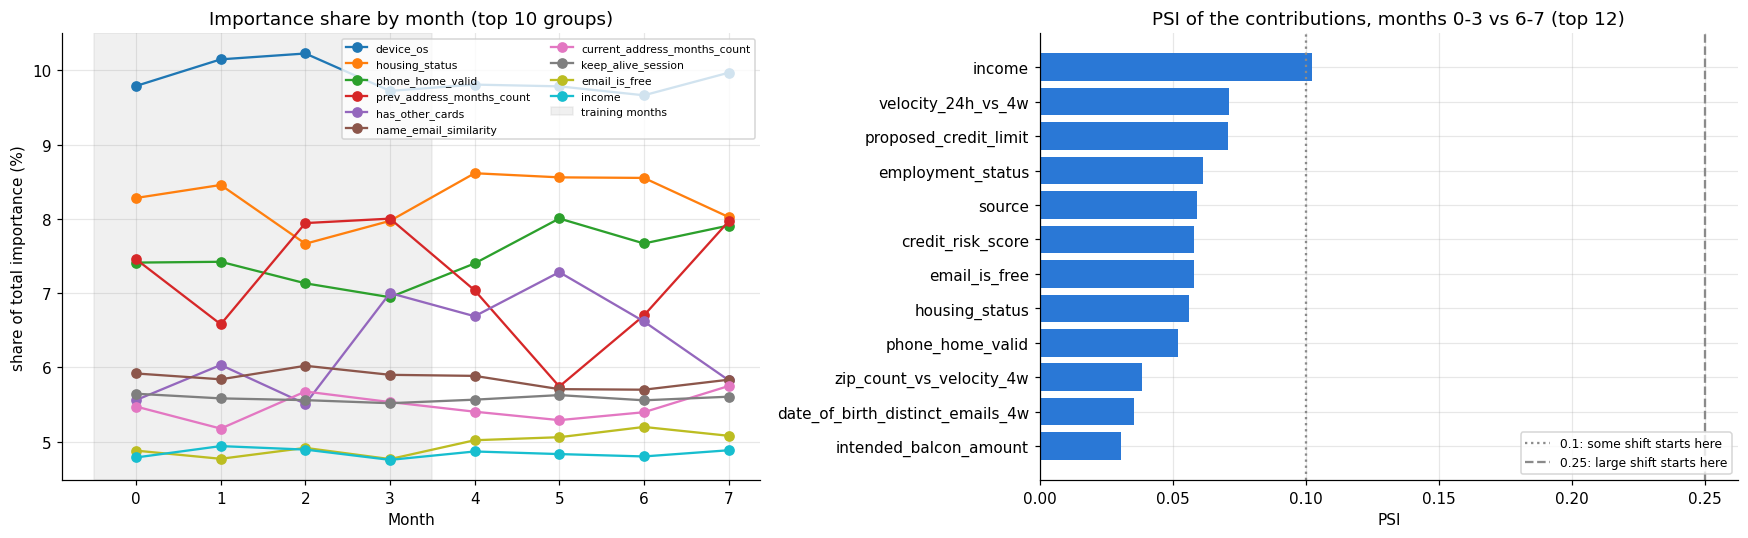

Groups with PSI of their contributions above 0.1: ['income']


,0,1,2,3,4,5,6,7
device_os,0.522,0.547,0.553,0.533,0.527,0.518,0.518,0.541
housing_status,0.442,0.456,0.415,0.437,0.463,0.453,0.458,0.435
phone_home_valid,0.395,0.400,0.386,0.380,0.397,0.424,0.411,0.429
prev_address_months_count,0.398,0.355,0.430,0.438,0.378,0.304,0.359,0.432
has_other_cards,0.297,0.325,0.298,0.383,0.359,0.386,0.355,0.316
name_email_similarity,0.316,0.315,0.326,0.323,0.316,0.302,0.306,0.316
current_address_months_count,0.292,0.279,0.307,0.303,0.290,0.280,0.289,0.312
keep_alive_session,0.301,0.301,0.301,0.302,0.299,0.298,0.298,0.304
email_is_free,0.260,0.257,0.266,0.261,0.270,0.268,0.279,0.275
income,0.255,0.266,0.265,0.260,0.261,0.256,0.257,0.265


In [36]:
months = sorted(monthly_importance)
importance_by_month = pd.DataFrame(monthly_importance, index=GROUP_NAMES).loc[grouped_importance.index]
share_by_month = importance_by_month / importance_by_month.sum()

early = np.vstack([monthly_sample[m] for m in months if m <= 3])
late = np.vstack([monthly_sample[m] for m in months if m >= 6])
contribution_psi = pd.Series({g: population_stability_index(early[:, j], late[:, j])
                              for j, g in enumerate(GROUP_NAMES)}).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for group in grouped_importance.index[:10]:
    axes[0].plot(months, share_by_month.loc[group] * 100, marker='o', label=group)
axes[0].axvspan(-0.5, 3.5, color=GREY, alpha=0.12, label='training months')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('share of total importance (%)')
axes[0].set_title('Importance share by month (top 10 groups)')
axes[0].legend(fontsize=7, ncol=2)

top_psi = contribution_psi.head(12).iloc[::-1]
axes[1].barh(top_psi.index, top_psi.values, color=BLUE)
axes[1].axvline(0.1, color=GREY, linestyle=':', linewidth=1.5, label='0.1: some shift starts here')
axes[1].axvline(0.25, color=GREY, linestyle='--', linewidth=1.5, label='0.25: large shift starts here')
axes[1].set_title('PSI of the contributions, months 0-3 vs 6-7 (top 12)')
axes[1].set_xlabel('PSI')
axes[1].legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

print('Groups with PSI of their contributions above 0.1:', list(contribution_psi.index[contribution_psi > 0.1]))
(importance_by_month.head(12)).round(3)

## **12. Rare but Large Effects**
Mean |contribution| can hide a feature that is usually quiet but sometimes decisive (e.g. `device_distinct_emails_8w = 2` added about +1.1 to one application although its average importance is low). For each group, on the test months (seed 0):
- the mean and 99th percentile of |contribution|, and the largest,
- the share of applications where the group is the **single largest** contributor,
- the share of applications where its |contribution| is above 0.5 (calibrated log-odds).
- **"Large" contribution: above 0.5 calibrated log-odds.**: A contribution of 0.5 multiplies the odds by about 1.65. A round number, not a statistical threshold. The 99th percentile is also shown.

A large ratio of the 99th percentile to the mean marks a feature that matters rarely but strongly.

**Results**
- Two features matter rarely but strongly:
    - device_distinct_emails_8w has a mean of only 0.094 but a 99th percentile of 0.913, a ratio of 9.7. It exceeds 0.5 in 1.4% of applications and reaches 1.45 at most.
    - foreign_request has the largest ratio (16.1), with a mean of 0.027 and a 99th percentile of 0.438. It rarely drives a decision (top contributor in 0.04% of applications, above 0.5 in 0.4%).
- proposed_credit_limit has the largest single effect. Its maximum is 1.75 while the 99th percentile is only 0.214. This is the jump for limits of 1,900 and above from section 7.2 (about +1.1 to +1.2). Fewer than 1% of applications are affected (0.85% above 0.5).
- A handful of groups decide most cases. The single largest contributor is prev_address_months_count in 23.1% of applications, has_other_cards in 19.7%, housing_status in 19.4% and device_os in 17.8%. That is about 80% together, and phone_home_valid (6.0%) and employment_status (4.5%) add 10 points.
- Binary and categorical features have flat effects. device_os, phone_home_valid, keep_alive_session and email_is_free have ratios of only 1.3–1.6, because every application gets a contribution of about the same size. device_os exceeds 0.5 in 56.9% of applications, phone_home_valid in 43.7% and housing_status in 33.8%.
- Some groups never matter. source, payment_type, phone_mobile_valid, zip_count_vs_velocity_4w and velocity_6h_vs_24h are never the top contributor and never exceed 0.5, so the model effectively ignores them.

In [37]:
absolute = np.abs(grouped_shap[0]) * A[0]
top_contributor = absolute.argmax(axis=1)
rare = pd.DataFrame({
    'mean |contribution|': absolute.mean(axis=0),
    '99th percentile |contribution|': np.quantile(absolute, 0.99, axis=0),
    'largest |contribution|': absolute.max(axis=0),
    'top contributor in (% of applications)': np.bincount(top_contributor, minlength=len(GROUP_NAMES)) / len(absolute) * 100,
    '|contribution| > 0.5 in (% of applications)': (absolute > 0.5).mean(axis=0) * 100,
}, index=GROUP_NAMES)
rare['99th percentile / mean'] = rare['99th percentile |contribution|'] / rare['mean |contribution|']
rare.sort_values('99th percentile / mean', ascending=False).round(3)

,mean |contribution|,99th percentile |contribution|,largest |contribution|,top contributor in (% of applications),|contribution| > 0.5 in (% of applications),99th percentile / mean
foreign_request,0.027,0.438,0.780,0.040,0.413,16.129999
device_distinct_emails_8w,0.094,0.913,1.453,1.140,1.365,9.720000
phone_mobile_valid,0.037,0.197,0.240,0.000,0.000,5.273000
employment_status,0.206,1.038,1.400,4.476,10.071,5.044000
credit_risk_score,0.147,0.723,1.522,0.750,3.673,4.916000
velocity_6h_vs_24h,0.027,0.130,0.362,0.000,0.000,4.852000
date_of_birth_distinct_emails_4w,0.116,0.551,0.780,0.154,2.286,4.746000
bank_branch_count_8w,0.166,0.772,1.065,0.827,2.973,4.647000
intended_balcon_amount,0.139,0.594,1.047,0.471,2.395,4.278000
session_length_in_minutes,0.097,0.406,0.878,0.139,0.524,4.204000


## **13. What Drives the Gaps of the Groups?**
Some groups are flagged far more often than others. Is a group flagged more because of its own feature, or because other features act as proxies for belonging to it? This section answers that for the groups with the largest FPR gaps in notebook 04's customer-group analysis: housing status BA, Windows devices and employment status CC. **The age gap is analysed in notebook 06** (section 4.3, "Which features carry the difference?"), so it is not repeated here; the age 50+ row is shown for reference only.

For each group, the **genuine** applicants in the group are compared with the other genuine applicants (test months, seed 0, calibrated log-odds):
- the FPR at the frozen threshold inside and outside the group (the model's *behaviour*),
- the fraud rate in the group (notebook 04 found that group FPR and group fraud rate rank the groups almost identically, Spearman 0.98),
- the difference in average calibrated log-odds, split into the contribution of each feature group. The pieces add up to the total difference.

For a group defined by a feature (housing BA is a value of `housing_status`), that feature carries part of the gap by construction. The interesting part is the remainder, which comes from proxies.

**Results**
| group | share of test apps | fraud rate in / outside | FPR in / outside (ratio) | gap in mean log-odds | carried by its own feature |
|---|---|---|---|---|---|
| age 50+ (reference; see notebook 06) | 16.5% | 2.9% / 1.1% | 12.7% / 3.9% (3.3x) | 0.93 | 49% (`customer_age`) |
| housing BA | 19.5% | 4.5% / 0.7% | 20.7% / 1.7% (11.9x) | 1.90 | 62% (`housing_status`) |
| device OS Windows | 24.7% | 3.2% / 0.8% | 13.9% / 2.6% (5.4x) | 1.39 | 81% (`device_os`) |
| employment CC | 3.2% | 3.1% / 1.3% | 12.5% / 5.1% (2.5x) | 0.87 | 18% (`employment_status`) |

- **Every flagged-more group has a higher fraud rate.** The model flags in proportion to risk, which is why the FPR gaps follow the fraud rates.
- **Housing BA has the largest gap by far** (FPR ratio 11.9). The rest of its gap is spread over prev_address (9%), income (6%), current_address (6%) and credit_risk_score (6%).
- **Windows is almost entirely its own feature** (81%), so there is little proxy effect to remove.
- **Employment CC is an age finding.** Only 18% of its gap comes from `employment_status`. The rest is `customer_age` (45%) and `date_of_birth_distinct_emails_4w` (29%), partly offset by `phone_home_valid` (-26%), because older applicants are over-represented in this small group.

In [38]:
# Used in later parts of the notebook
is_50_plus = test['customer_age'].to_numpy() >= 50
genuine = y_test == 0
contribution_all = grouped_shap[0] * A[0]

In [39]:
SUBGROUPS = {
    'age 50+': (is_50_plus, ['customer_age']),
    'housing status BA': ((X_test['housing_status'] == 'BA').to_numpy(), ['housing_status']),
    'device OS windows': ((X_test['device_os'] == 'windows').to_numpy(), ['device_os']),
    'employment status CC': ((X_test['employment_status'] == 'CC').to_numpy(), ['employment_status']),
}

summary_rows = []
top_contributors = {}
for name, (member, defining) in SUBGROUPS.items():
    inside, outside = genuine & member, genuine & ~member
    difference = pd.Series(contribution_all[inside].mean(axis=0) - contribution_all[outside].mean(axis=0), index=GROUP_NAMES)
    summary_rows.append({
        'group': name,
        'share of test applications': member.mean(),
        'fraud rate in the group': y_test[member].mean(),
        'fraud rate outside': y_test[~member].mean(),
        'FPR in the group': flagged[inside].mean(),
        'FPR outside': flagged[outside].mean(),
        'FPR ratio': flagged[inside].mean() / flagged[outside].mean(),
        'gap in mean log-odds': difference.sum(),
        'share carried by the defining feature': difference[defining].sum() / difference.sum(),
    })
    top_contributors[name] = pd.DataFrame({'difference': difference, 'share of the gap': difference / difference.sum()}).sort_values(
        'difference', key=np.abs, ascending=False).head(5)

for name, table in top_contributors.items():
    print(f'{name}: the 5 groups with the largest part of the gap')
    print(table.round(3).to_string())
    print()
pd.DataFrame(summary_rows).set_index('group').round(3)

age 50+: the 5 groups with the largest part of the gap
                                  difference  share of the gap
customer_age                           0.461             0.493
housing_status                         0.170             0.182
prev_address_months_count              0.149             0.159
phone_home_valid                      -0.148            -0.159
date_of_birth_distinct_emails_4w       0.133             0.142

housing status BA: the 5 groups with the largest part of the gap
                              difference  share of the gap
housing_status                     1.170             0.618
prev_address_months_count          0.179             0.094
income                             0.117             0.062
current_address_months_count       0.108             0.057
credit_risk_score                  0.106             0.056

device OS windows: the 5 groups with the largest part of the gap
                   difference  share of the gap
device_os               1.116    

,share of test applications,fraud rate in the group,fraud rate outside,FPR in the group,FPR outside,FPR ratio,gap in mean log-odds,share carried by the defining feature
group,,,,,,,,
age 50+,0.165,0.029,0.011,0.127,0.039,3.277,0.934,0.493
housing status BA,0.195,0.045,0.007,0.207,0.017,11.875,1.895,0.618
device OS windows,0.247,0.032,0.008,0.139,0.026,5.388,1.385,0.805
employment status CC,0.032,0.031,0.013,0.125,0.051,2.469,0.871,0.177


## **14. Sanity Table**
**Purpose.** A one-page check that the most important groups make business sense, and that none of them is a leak: a feature known only **after** an investigation would be unusable at decision time.

**Method.** One row per group (all 28), ordered by SHAP rank. The SHAP and permutation ranks and the model direction come from this notebook (sections 3, 5 and 7). The meaning column follows the BAF datasheet. The datasheet does not say when each value becomes known, so the **timing** column is my reading of the feature descriptions and could not be verified. The business-story column is also my inference, not from the datasheet.

**Results**
- **No leak is proven, but two are doubtful.** The datasheet gives no timing for any feature, so "known at decision time" is an assumption from the descriptions. `days_since_request` (days passed since the application was done) is the most doubtful, since a count after the application cannot be known at decision time. `credit_risk_score` is an internal score whose computation is not described. Both should be confirmed with the data owner before anyone relies on the model.
- **Some effects have no story.** The anonymised codes for housing and employment cannot be explained, and the up-and-down shape of `current_address_months_count` and the jagged `bank_branch_count_8w` have no obvious business reason, although section 7.4 shows they are in the data.
- **Several top groups are age proxies** (`housing_status`, `phone_home_valid`, `employment_status`), and `customer_age` is flagged as a protected attribute (see notebook 06).

In [50]:
SANITY = {
    'device_os': ('operating system of the device used (Windows, macOS, Linux, X11 or other)', 'datasheet silent; assumed yes, recorded at application',
                  'Windows 2.2% vs Linux 0.4% fraud in months 0-3; fraud attempts may come from different devices', ''),
    'housing_status': ('current residential status of the applicant (7 anonymised codes, BA-BG)', 'datasheet silent; assumed yes, stated on the application',
                       'BA has 3.35% fraud, BE 0.3%; the codes are anonymised, so no story can be told from the data alone',
                       'meaning of the codes unknown; age proxy (AUC 0.67 for 50+)'),
    'phone_home_valid': ('validity of the provided home phone', 'datasheet silent; assumed yes',
                         'an invalid number is a typical sign of a made-up identity', 'age proxy (AUC 0.62 for 50+)'),
    'prev_address_months_count': ('months at the previous registered address, if applicable; -1 (missing) if none', 'datasheet silent; assumed yes',
                                  'no previous address on record goes with 5x the fraud rate (1.28% vs 0.27%)',
                                  'direction among present values differs from the EDA table (the -1 codes)'),
    'has_other_cards': ('applicant has other cards from the same banking company', 'datasheet silent; assumed yes',
                        'probably an existing customer; lower risk is the model\'s reading, not stated in the datasheet', ''),
    'name_email_similarity': ('similarity between the email and the applicant\'s name (0-1, higher is more similar)', 'datasheet silent; assumed yes',
                              'a very different email can mean a made-up identity', ''),
    'current_address_months_count': ('months at the currently registered address; -1 if missing', 'datasheet silent; assumed yes',
                                     'no obvious story for the rise at 50-100 months and the fall after 150',
                                     'non-monotone and an age proxy: explain before using in the report'),
    'keep_alive_session': ('the user\'s option on session logout (binary)', 'to confirm: a logout choice may come after the application',
                           'genuine customers more often keep sessions alive',
                           'the datasheet does not say what value 1 means or when it is recorded'),
    'email_is_free': ('whether the email domain is free or paid', 'datasheet silent; assumed yes',
                      'free addresses are easy to create in bulk ', ''),
    'income': ('annual income of the applicant, in decile form (0.1-0.9)', 'datasheet silent; assumed yes',
               'higher income goes with more fraud (0.5% to 1.9%); the top band adds about +0.4 to +0.5',
               'unverified; check group FPR for the top band (notebook 04)'),
    'employment_status': ('employment status of the applicant (7 anonymised codes, CA-CG)', 'datasheet silent; assumed yes, stated',
                          'CC has 2.3% fraud, CF 0.2%; codes anonymised', 'age proxy (AUC 0.61 for 50+)'),
    'customer_age': ('age in years, rounded to the decade (10-90)', 'datasheet silent; assumed yes',
                     'fraud rate rises with age in this data',
                     'protected attribute: see notebook 06 (section 4)'),
    'bank_branch_count_8w': ('number of total applications at the selected bank branch in the last 8 weeks', 'datasheet silent; assumed yes if the window ends at the application',
                             'branch volume; the jagged effect has no obvious story', 'check stability (section 7.4)'),
    'credit_risk_score': ('internal score of application risk (range -191 to 389)', 'to confirm',
                          'higher score goes with more fraud, mostly above about 230',
                          'the datasheet does not say how or when it is computed; confirm it is known before the decision and not influenced by fraud checks'),
    'days_since_request': ('number of days passed since the application was done (range 0-79)', 'to confirm: possible leak',
                           'very irregular effect at small values (section 7.3)',
                           'a count of days since the application is probably not known at decision time; confirm the definition with the data owner'),
    'bank_months_count': ('age of the previous bank account in months, if held; -1 (missing) if none', 'datasheet silent; assumed yes',
                          'missing for 25% of applications', ''),
    'intended_balcon_amount': ('initial transferred amount for the application; negative values are missing', 'datasheet silent; assumed yes',
                               'missing for 74% of applications', ''),
    'date_of_birth_distinct_emails_4w': ('number of emails for applicants with the same date of birth in the last 4 weeks',
                                         'datasheet silent; assumed yes, a past window',
                                         'many emails for one birth date suggests repeated attempts',
                                         'strongest age proxy (AUC 0.81 for 50+); drifts (PSI 0.46 in the EDA)'),
    'session_length_in_minutes': ('length of the user session on the banking website in minutes; -1 if missing', 'datasheet silent; assumed yes', '', ''),
    'device_distinct_emails_8w': ('number of distinct emails on the banking website from the used device in the last 8 weeks (range -1 to 2)',
                                  'datasheet silent; assumed yes, a past window',
                                  'one device used for many emails suggests repeated attempts', 'rare large effects (section 12)'),
    'proposed_credit_limit': ('applicant\'s proposed credit limit (range 200-2000)', 'datasheet silent; assumed yes',
                              'non-monotone: strong push towards fraud at 1500 and above, especially 2000 (section 7.2)',
                              'rare large effects (section 12); the Spearman sign in section 7.1 is misleading'),
    'zip_count_vs_velocity_4w': ('ratio of two application counts (built in notebook 02 from `zip_count_4w` and the velocity columns; not in the datasheet)',
                                 'datasheet silent; assumed yes, past windows',
                                 'relative level of recent activity', 'built to avoid drift (notebook 02)'),
    'payment_type': ('credit payment plan type (5 anonymised values)', 'datasheet silent; assumed yes', 'barely matters to the model (section 12)', ''),
    'source': ('online source of the application: browser (INTERNET) or app (TELEAPP)', 'datasheet silent; assumed yes', 'barely matters to the model (section 12)', ''),
    'foreign_request': ('whether the origin country of the request differs from the bank\'s country', 'datasheet silent; assumed yes',
                        'rarely decisive, but large when it is (section 12)', ''),
    'phone_mobile_valid': ('validity of the provided mobile phone', 'datasheet silent; assumed yes', 'barely matters to the model (section 12)', ''),
    'velocity_24h_vs_4w': ('ratio of the average application velocity in the last 24 hours to the last 4 weeks (built in notebook 02; not in the datasheet)', 'datasheet silent; assumed yes, past windows',
                           'relative level of recent activity', 'built to avoid drift (notebook 02); barely matters to the model'),
    'velocity_6h_vs_24h': ('ratio of the average application velocity in the last 6 hours to the last 24 hours (built in notebook 02; not in the datasheet)', 'datasheet silent; assumed yes, past windows',
                           'relative level of recent activity', 'built to avoid drift (notebook 02); barely matters to the model'),
}

rows = []
for group in grouped_importance.index:
    meaning, timing, story, follow_up = SANITY.get(group, ('', '', '', ''))
    rows.append({
        'group': group,
        'SHAP rank': int(comparison.loc[group, 'SHAP rank']),
        'permutation rank': int(comparison.loc[group, 'permutation rank (recall)']),
        'model direction': direction_table.loc[group, 'model direction'] if group in direction_table.index else 'categorical (section 7.5)',
        'meaning': meaning, 'known at decision time?': timing, 'business story': story, 'to follow up': follow_up,
    })
sanity_table = pd.DataFrame(rows).set_index('group')
pd.set_option('display.max_colwidth', 90)
sanity_table

,SHAP rank,permutation rank,model direction,meaning,known at decision time?,business story,to follow up
group,,,,,,,
device_os,1,2,categorical (section 7.5),"operating system of the device used (Windows, macOS, Linux, X11 or other)","datasheet silent; assumed yes, recorded at application",Windows 2.2% vs Linux 0.4% fraud in months 0-3; fraud attempts may come from different...,
housing_status,2,1,categorical (section 7.5),"current residential status of the applicant (7 anonymised codes, BA-BG)","datasheet silent; assumed yes, stated on the application","BA has 3.35% fraud, BE 0.3%; the codes are anonymised, so no story can be told from th...",meaning of the codes unknown; age proxy (AUC 0.67 for 50+)
phone_home_valid,3,3,higher -> less fraud,validity of the provided home phone,datasheet silent; assumed yes,an invalid number is a typical sign of a made-up identity,age proxy (AUC 0.62 for 50+)
prev_address_months_count,4,6,higher -> more fraud,"months at the previous registered address, if applicable; -1 (missing) if none",datasheet silent; assumed yes,no previous address on record goes with 5x the fraud rate (1.28% vs 0.27%),direction among present values differs from the EDA table (the -1 codes)
has_other_cards,5,4,higher -> less fraud,applicant has other cards from the same banking company,datasheet silent; assumed yes,"probably an existing customer; lower risk is the model's reading, not stated in the da...",
name_email_similarity,6,5,higher -> less fraud,"similarity between the email and the applicant's name (0-1, higher is more similar)",datasheet silent; assumed yes,a very different email can mean a made-up identity,
current_address_months_count,7,11,higher -> more fraud,months at the currently registered address; -1 if missing,datasheet silent; assumed yes,no obvious story for the rise at 50-100 months and the fall after 150,non-monotone and an age proxy: explain before using in the report
keep_alive_session,8,8,higher -> less fraud,the user's option on session logout (binary),to confirm: a logout choice may come after the application,genuine customers more often keep sessions alive,the datasheet does not say what value 1 means or when it is recorded
email_is_free,9,7,higher -> more fraud,whether the email domain is free or paid,datasheet silent; assumed yes,free addresses are easy to create in bulk,


In [41]:
# Save feature dictionary

from pathlib import Path

output_dir = Path('../outputs/interpretability')
output_dir.mkdir(parents=True, exist_ok=True)
file_path = output_dir / 'feature_dictionary.csv'
sanity_table.to_csv(file_path)
print(f'Saved {len(sanity_table)} rows to {file_path}')

Saved 28 rows to ..\outputs\interpretability\feature_dictionary.csv


## **15. Accuracy-Cost Experiments (the Only Place Where Models Are Retrained)**
**Purpose.** How much accuracy does a simpler, more interpretable model give up, and does the frozen model's complexity explain the age gap?

**Method.** The frozen model is an XGBoost with trees of depth 3, so it is already shallow. Notebook 02's Optuna search was allowed depths 3-10 and picked 3, the lowest value it could pick, so the search never tried the simpler models below. Candidates:
- **depth 2**: pairwise interactions only,
- **depth 1**: every tree splits on one feature only, so the model is a plain **additive** model (a sum of one curve per feature, like a GAM). Its explanation is the model itself, with no interactions to explain,
- **depth 3 with monotonic constraints**: the score may only rise with the credit risk score and with income, and only fall with name-email similarity. These are the features whose section 7.3 plots are roughly monotone and whose direction has a business story (a higher risk score is riskier; a name unlike the email is a classic sign of a made-up identity). A further candidate was `keep_alive_session`, but it is a 0/1 column, for which a constraint is a single sign and changes nothing the tree could not already learn, so it was left out. `customer_age` is deliberately left unconstrained: forcing a direction on a protected attribute would be a fairness decision, not an interpretability one. The constraints are a guess, and what they cost is exactly what the experiment measures.
- **logistic regression** with notebook 02's starting settings (`C = 1`), the plain-linear reference. Its tuned settings (trial 28) were not saved to `configs/`, and tuning moved it by only +0.006, so the starting settings are close.
- An **Explainable Boosting Machine** (a modern additive model) can be added with `RUN_EBM = True`.
- **Experiments: 3 seeds, depth 1 with 477 and 1,500 trees, depth 2 with 477 and 954, monotone on credit risk, income and name-email similarity, selected on month 4.** Seed spread is about 0.002, far below the sampling interval, so 3 seeds suffice. Shallower trees need more trees, and the multiples are rough, which is why both counts are tried. The monotone features have roughly monotone plots and a business direction. Age is left free on purpose. Month 4 is the validation month, so the test months stay untouched.

**Rules, so that nothing here can steer the frozen model:**
1. Every XGBoost candidate is trained on months 0-3 with the **frozen hyperparameters** except the one named. A depth-1 or depth-2 model has less capacity per tree, so it also gets more trees: **1,500** for depth 1 (about 3x the frozen 477) and **954** for depth 2 (2x). These are rough multiples, not a tuned value; both counts are tried so that month 4 shows whether more trees help.
2. Candidates are compared on **month 4 only** (the validation month of notebook 02). Months 6-7 are not looked at while choosing.
3. Months 6-7 are reported **once**, in section 15.2. Nothing is changed after seeing it.
4. Nothing from this section flows back into the frozen model, the thresholds or the calibration. Every candidate gets its own threshold: 5% FPR on month 5, as in notebook 02.

**Seeds.** Only **3** seeds are used to keep the run time reasonable: notebook 04 (section 4) found a seed standard deviation of about 0.002 in recall at 5% FPR, small against the +/-0.018 sampling interval of one model on the test months. Change `EXPERIMENT_SEEDS` to use 5. Logistic regression gives the same result for every seed, so it is fitted once.

**Results**
- **Simpler models lose little.** On months 6-7 (reported once) recall at 5% FPR is 0.548 for the frozen model, 0.550 for depth 2, 0.551 for depth 1 with 1,500 trees and 0.547 for the monotone model. Differences below 0.01 are not real.
- **Logistic regression is clearly worse:** recall at 5% FPR 0.516 (-0.032), PR-AUC 0.169 against 0.197.
- **The age gap does not come from model complexity.** Predictive equality stays between 0.29 and 0.32 for every model, including the depth-1 additive one (0.293) and logistic regression (0.318).

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

EXPERIMENT_SEEDS = [0, 1, 2]
RUN_EBM = False   # True: also fit an Explainable Boosting Machine (needs `pip install interpret`; takes several minutes)

BASE_PARAMS = dict(final_model['params'])
MONOTONE = {'credit_risk_score': 1, 'income': 1, 'name_email_similarity': -1}
monotone_tuple = tuple(MONOTONE.get(name, 0) for name in FEATURE_NAMES)

# name -> (settings that differ from the frozen ones, monotonic constraints?, family)
CANDIDATES = {
    'refit of the frozen settings (depth 3, 477 trees)': ({}, False, 'depth 3'),
    'depth 2, 477 trees': ({'max_depth': 2}, False, 'depth 2'),
    'depth 2, 954 trees': ({'max_depth': 2, 'n_estimators': 954}, False, 'depth 2'),
    'depth 1, 477 trees': ({'max_depth': 1}, False, 'depth 1'),
    'depth 1, 1500 trees': ({'max_depth': 1, 'n_estimators': 1500}, False, 'depth 1'),
    'depth 3 + monotonic constraints': ({}, True, 'monotone'),
}
LR_NAME = 'logistic regression (notebook 02 starting settings)'

month4 = base[base['month'] == 4]
X_month4 = make_features(month4, **FEATURES)
y_month4 = month4[TARGET].to_numpy()
y_month5 = month5[TARGET].to_numpy()

# Copied from notebook 02 (section 4.1, make_model): the columns with long right tails are log-transformed for
# logistic regression only; categories under 0.5% of rows are merged into one "infrequent" column.
LOG_COLUMNS = ['days_since_request', 'prev_address_months_count', 'session_length_in_minutes',
               'bank_branch_count_8w', 'intended_balcon_amount', 'current_address_months_count']


def make_logistic_regression():
    log_columns = Pipeline([('fill', SimpleImputer(strategy='median')), ('log', FunctionTransformer(np.log1p)),
                            ('scale', StandardScaler())])
    categories = OneHotEncoder(min_frequency=0.005, handle_unknown='infrequent_if_exist', sparse_output=False)
    other_columns = Pipeline([('fill', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    prepare = ColumnTransformer([('log', log_columns, LOG_COLUMNS), ('categories', categories, categorical_columns)],
                                remainder=other_columns)
    return Pipeline([('prepare', prepare), ('model', LogisticRegression(C=1.0, max_iter=1000, random_state=0))])


def threshold_at_fpr(y_true, scores, target_fpr=TARGET_FPR):
    """Copied from notebook 02: flag scores >= the returned threshold to stay within target_fpr."""
    fpr, tpr, thresholds_here = roc_curve(y_true, scores)
    i = np.searchsorted(fpr, target_fpr, side='right') - 1
    return thresholds_here[i]


fitted = {}          # candidate -> one fitted model per seed
fitted_seeds = {}
family_of = {}
validation_rows = []


def add_validation_row(name, seed, model):
    scores4 = model.predict_proba(X_month4)[:, 1]
    validation_rows.append({'candidate': name, 'seed': seed, 'recall@5%FPR': recall_at_fpr(y_month4, scores4),
                            'PR-AUC': average_precision_score(y_month4, scores4),
                            'ROC-AUC': roc_auc_score(y_month4, scores4)})


start = time.time()
for name, (override, monotone, family) in CANDIDATES.items():
    fitted[name], fitted_seeds[name], family_of[name] = [], list(EXPERIMENT_SEEDS), family
    for seed in EXPERIMENT_SEEDS:
        settings = {**BASE_PARAMS, **override}
        if monotone:
            settings['monotone_constraints'] = monotone_tuple
        model = xgb.XGBClassifier(**settings, random_state=seed, tree_method='hist', enable_categorical=True)
        model.fit(X_train, y_train)
        fitted[name].append(model)
        add_validation_row(name, seed, model)
    print(f'{name}: done, {(time.time() - start) / 60:.1f} min so far')

logistic = make_logistic_regression().fit(X_train, y_train)
fitted[LR_NAME], fitted_seeds[LR_NAME], family_of[LR_NAME] = [logistic], [0], 'logistic regression'
add_validation_row(LR_NAME, 0, logistic)
print(f'{LR_NAME}: done, {(time.time() - start) / 60:.1f} min so far')

refit of the frozen settings (depth 3, 477 trees): done, 0.7 min so far
depth 2, 477 trees: done, 1.4 min so far
depth 2, 954 trees: done, 2.7 min so far
depth 1, 477 trees: done, 3.3 min so far
depth 1, 1500 trees: done, 4.9 min so far
depth 3 + monotonic constraints: done, 5.7 min so far
logistic regression (notebook 02 starting settings): done, 5.8 min so far


In [43]:
if RUN_EBM:
    from interpret.glassbox import ExplainableBoostingClassifier
    name = 'EBM (additive, no interactions)'
    ebm = ExplainableBoostingClassifier(interactions=0, random_state=0)
    ebm.fit(X_train, y_train)
    fitted[name], fitted_seeds[name], family_of[name] = [ebm], [0], 'EBM'
    add_validation_row(name, 0, ebm)
    print('EBM fitted (one seed)')
else:
    print('RUN_EBM is False: no EBM')

RUN_EBM is False: no EBM


### **15.1 Choosing on Month 4**
**Purpose.** Pick one candidate per family without looking at months 6-7.

**Method.** Month-4 results only (mean over 3 seeds). Within each family, the candidate with the highest recall at 5% FPR is chosen.

**Results**
- **Chosen:** the refit of the frozen settings (0.578), depth 2 with 477 trees (0.576), depth 1 with 1,500 trees (0.572), the monotone model (0.572) and logistic regression (0.539).
- **More trees help depth 1:** 1,500 trees give 0.572 against 0.562 for 477. For depth 2, 954 trees (0.575) are not better than 477 (0.576).
- **The seed spread is small** (0.001-0.005), so only differences above about 0.005 mean anything.

In [44]:
validation = pd.DataFrame(validation_rows)
validation_table = validation.groupby('candidate', sort=False).agg(
    **{'recall@5%FPR (mean)': ('recall@5%FPR', 'mean'), 'recall@5%FPR (std over seeds)': ('recall@5%FPR', 'std'),
       'PR-AUC': ('PR-AUC', 'mean'), 'ROC-AUC': ('ROC-AUC', 'mean')})
validation_table['family'] = [family_of[name] for name in validation_table.index]
chosen = validation_table.groupby('family')['recall@5%FPR (mean)'].idxmax()
validation_table['chosen in its family'] = validation_table.index.isin(chosen.values)
print('Chosen on month 4:', list(chosen.values))
validation_table.round(4)

Chosen on month 4: ['depth 1, 1500 trees', 'depth 2, 477 trees', 'refit of the frozen settings (depth 3, 477 trees)', 'logistic regression (notebook 02 starting settings)', 'depth 3 + monotonic constraints']


,recall@5%FPR (mean),recall@5%FPR (std over seeds),PR-AUC,ROC-AUC,family,chosen in its family
candidate,,,,,,
"refit of the frozen settings (depth 3, 477 trees)",0.5778,0.0050,0.1861,0.9110,depth 3,True
"depth 2, 477 trees",0.5762,0.0017,0.1866,0.9114,depth 2,True
"depth 2, 954 trees",0.5751,0.0018,0.1877,0.9115,depth 2,False
"depth 1, 477 trees",0.5622,0.0024,0.1779,0.9092,depth 1,False
"depth 1, 1500 trees",0.5721,0.0011,0.1853,0.9109,depth 1,True
depth 3 + monotonic constraints,0.5719,0.0021,0.1853,0.9102,monotone,True
logistic regression (notebook 02 starting settings),0.5386,NaN,0.1514,0.9003,logistic regression,True


### **15.2 Months 6-7, Reported Once**
**Purpose.** Report every chosen candidate on the test months, once, with nothing changed afterwards.

**Method.** Each candidate gets its own threshold (5% of genuine applicants flagged on month 5) and is scored on months 6-7 next to the frozen model. The refit should reproduce the frozen model, and notebook 04 found a 95% interval of about +/-0.018 for one model, so differences below about 0.01 should not be read as real.

**Results**
- **The refit reproduces the frozen model:** recall at 5% FPR 0.5481 against 0.5482. Its scores are not bit-for-bit identical (correlation 0.991), because this notebook was run in a different environment from notebook 02. In notebook 02’s environment the refit is identical.
- **Simpler XGBoost models match the frozen one** (recall at 5% FPR +0.002 for depth 2, +0.003 for depth 1 with 1,500 trees, -0.001 for the monotone model). Logistic regression loses 0.032.
- **No model reduces the age gap:** predictive equality is 0.29-0.32 in every row.

In [45]:
refit_scores = fitted['refit of the frozen settings (depth 3, 477 trees)'][0].predict_proba(X_test)[:, 1]
print(f'Refit (seed 0) vs the frozen seed-0 model: Spearman correlation of the scores {pd.Series(refit_scores).corr(pd.Series(score0), method="spearman"):.5f}, '
      f'mean absolute score difference {np.abs(refit_scores - score0).mean():.2e}, largest {np.abs(refit_scores - score0).max():.2e}')
print('If the correlation is not close to 1, check the seed and the weights of the refit; small differences can come from multi-threaded training, and the metrics below should then still agree to about 3 decimals.')


def candidate_metrics(model, threshold=None):
    scores_here = model.predict_proba(X_test)[:, 1]
    if threshold is None:
        threshold = threshold_at_fpr(y_month5, model.predict_proba(X_month5)[:, 1])
    flagged_here = scores_here >= threshold
    old = flagged_here[genuine & is_50_plus].mean()
    young = flagged_here[genuine & ~is_50_plus].mean()
    return {'recall@5%FPR': recall_at_fpr(y_test, scores_here), 'PR-AUC': average_precision_score(y_test, scores_here),
            'ROC-AUC': roc_auc_score(y_test, scores_here), 'recall at threshold': flagged_here[y_test == 1].mean(),
            'FPR at threshold': flagged_here[genuine].mean(), 'FPR 50+': old, 'FPR under 50': young,
            'predictive equality': min(old, young) / max(old, young)}


rows = [{'candidate': 'frozen model (5 seeds)', 'seed': seed, **candidate_metrics(models[seed], thresholds[seed])} for seed in SEEDS]
for name, model_list in fitted.items():
    for seed, model in zip(fitted_seeds[name], model_list):
        rows.append({'candidate': name, 'seed': seed, **candidate_metrics(model)})

test_table = pd.DataFrame(rows).drop(columns='seed').groupby('candidate', sort=False).mean()
test_table['difference in recall@5%FPR vs frozen'] = test_table['recall@5%FPR'] - test_table.loc['frozen model (5 seeds)', 'recall@5%FPR']
test_table['chosen on month 4'] = [name in set(chosen.values) for name in test_table.index]
test_table.round(4)

Refit (seed 0) vs the frozen seed-0 model: Spearman correlation of the scores 0.99068, mean absolute score difference 1.20e-02, largest 2.68e-01
If the correlation is not close to 1, check the seed and the weights of the refit; small differences can come from multi-threaded training, and the metrics below should then still agree to about 3 decimals.


,recall@5%FPR,PR-AUC,ROC-AUC,recall at threshold,FPR at threshold,FPR 50+,FPR under 50,predictive equality,difference in recall@5%FPR vs frozen,chosen on month 4
candidate,,,,,,,,,,
frozen model (5 seeds),0.5482,0.1968,0.8937,0.5615,0.0531,0.1266,0.0389,0.3072,0.0000,False
"refit of the frozen settings (depth 3, 477 trees)",0.5481,0.1966,0.8936,0.5591,0.0531,0.1258,0.0390,0.3103,-0.0001,True
"depth 2, 477 trees",0.5504,0.1985,0.8941,0.5652,0.0539,0.1302,0.0392,0.3009,0.0022,True
"depth 2, 954 trees",0.5489,0.1981,0.8942,0.5625,0.0532,0.1283,0.0387,0.3017,0.0007,False
"depth 1, 477 trees",0.5409,0.1932,0.8911,0.5613,0.0551,0.1364,0.0393,0.2882,-0.0073,False
"depth 1, 1500 trees",0.5507,0.1994,0.8937,0.5680,0.0540,0.1325,0.0388,0.2932,0.0026,True
depth 3 + monotonic constraints,0.5468,0.1975,0.8932,0.5644,0.0537,0.1271,0.0395,0.3107,-0.0014,True
logistic regression (notebook 02 starting settings),0.5160,0.1689,0.8846,0.5334,0.0550,0.1283,0.0409,0.3184,-0.0322,True


### **15.3 The Cost Table**
**Purpose.** Put the interpretable candidates next to notebook 02's tuned models, to show what interpretability costs.

**Method.** Recall at 5% FPR, PR-AUC and ROC-AUC on month 4. The first three rows are typed in from notebook 02, section 6 (tuned, 5 seeds); if notebook 02 is re-run, update them. The rest are this section's results (3 seeds, 15.1). The last column is the difference in recall from the tuned frozen model. Months 6-7 stay in 15.2.

**Results**
- **Depth 2 gives up almost nothing** (0.576, -0.005 from the frozen 0.582, and -0.002 from the refit with the same procedure).
- **Depth 1 (1,500 trees) and the monotone model give up about 0.01** on month 4 (0.572, -0.009 and -0.010; about -0.006 from the refit). On months 6-7 this disappears (15.2), so it should not be called a real loss.
- **Logistic regression gives up about 4 points** (0.539 starting settings, -0.043; tuned 0.545, -0.037).
- **LightGBM is level with XGBoost** (-0.005).
- **Seed spread is 0.001-0.005,** so differences below 0.005 are noise.

In [46]:
reported = pd.DataFrame({'recall@5%FPR': [0.5448, 0.5770, 0.5815], 'PR-AUC': [0.1523, 0.1833, 0.1869],
                         'ROC-AUC': [0.9007, 0.9115, 0.9111]},
                        index=['logistic regression, tuned (notebook 02)', 'LightGBM, tuned (notebook 02)',
                               'XGBoost, tuned = the frozen model (notebook 02)'])
reported['source'] = 'notebook 02, section 6: 5 seeds, month 4'
ours = validation_table[['recall@5%FPR (mean)', 'PR-AUC', 'ROC-AUC']].rename(columns={'recall@5%FPR (mean)': 'recall@5%FPR'})
ours['source'] = f'this notebook: {len(EXPERIMENT_SEEDS)} seeds, month 4'
cost_table = pd.concat([reported, ours])
cost_table['recall@5%FPR minus the frozen model'] = cost_table['recall@5%FPR'] - reported.iloc[2]['recall@5%FPR']
cost_table.round(4)

,recall@5%FPR,PR-AUC,ROC-AUC,source,recall@5%FPR minus the frozen model
"logistic regression, tuned (notebook 02)",0.5448,0.1523,0.9007,"notebook 02, section 6: 5 seeds, month 4",-0.0367
"LightGBM, tuned (notebook 02)",0.5770,0.1833,0.9115,"notebook 02, section 6: 5 seeds, month 4",-0.0045
"XGBoost, tuned = the frozen model (notebook 02)",0.5815,0.1869,0.9111,"notebook 02, section 6: 5 seeds, month 4",0.0000
"refit of the frozen settings (depth 3, 477 trees)",0.5778,0.1861,0.9110,"this notebook: 3 seeds, month 4",-0.0037
"depth 2, 477 trees",0.5762,0.1866,0.9114,"this notebook: 3 seeds, month 4",-0.0053
"depth 2, 954 trees",0.5751,0.1877,0.9115,"this notebook: 3 seeds, month 4",-0.0064
"depth 1, 477 trees",0.5622,0.1779,0.9092,"this notebook: 3 seeds, month 4",-0.0193
"depth 1, 1500 trees",0.5721,0.1853,0.9109,"this notebook: 3 seeds, month 4",-0.0094
depth 3 + monotonic constraints,0.5719,0.1853,0.9102,"this notebook: 3 seeds, month 4",-0.0096
logistic regression (notebook 02 starting settings),0.5386,0.1514,0.9003,"this notebook: 3 seeds, month 4",-0.0429


### **15.4 What a Depth-1 Model Looks Like**
**Purpose.** Show that the explanations of sections 3-12 do not depend on the model's depth.

**Method.** The depth-1 model chosen on month 4 is purely additive, so its TreeSHAP contributions are its own per-feature curves. The table compares its shares of total importance with the frozen model (shares, not raw values, because the two are on different log-odds scales). Nothing is chosen from this.

**Results**
- **The rankings agree** (Spearman 0.994). The top shares are almost identical: device_os 9.7% against 9.8%, housing_status 8.0% against 8.3%, phone_home_valid 8.2% against 7.7%.
- **Ranks differ by at most one place** in the top 12 (for example housing_status 3 against 2, customer_age 13 against 12).
- **Interactions add almost nothing:** a model with none matches the frozen one in recall (15.2) and importance.

In [47]:
depth1_name = chosen['depth 1']
depth1_model = fitted[depth1_name][0]
depth1_values, _, _ = contributions(depth1_model, X_test)
depth1_grouped = np.column_stack([depth1_values[:, index].sum(axis=1) for index in group_index.values()])

depth1_importance = pd.Series(np.abs(depth1_grouped).mean(axis=0), index=GROUP_NAMES)
shares = pd.DataFrame({'share, depth-1 model': depth1_importance / depth1_importance.sum(),
                       'share, frozen model': grouped_importance[MEAN].reindex(GROUP_NAMES) / grouped_importance[MEAN].sum()})
shares['rank, depth-1 model'] = shares['share, depth-1 model'].rank(ascending=False).astype(int)
shares['rank, frozen model'] = shares['share, frozen model'].rank(ascending=False).astype(int)
shares = shares.sort_values('share, frozen model', ascending=False)

print(f'Depth-1 model: {depth1_name}')
print('Spearman correlation of the two importance rankings: '
      f"{shares['rank, depth-1 model'].corr(shares['rank, frozen model'], method='spearman'):.3f}")
shares.head(12).round(3)

Depth-1 model: depth 1, 1500 trees
Spearman correlation of the two importance rankings: 0.994


,"share, depth-1 model","share, frozen model","rank, depth-1 model","rank, frozen model"
device_os,0.097,0.098,1,1
housing_status,0.080,0.083,3,2
phone_home_valid,0.082,0.077,2,3
prev_address_months_count,0.073,0.072,4,4
has_other_cards,0.067,0.062,5,5
name_email_similarity,0.059,0.058,6,6
current_address_months_count,0.057,0.057,8,7
keep_alive_session,0.058,0.057,7,8
email_is_free,0.053,0.051,9,9
income,0.050,0.049,10,10


### **15.5 Logistic Regression as a Fifth Importance Ranking**
**Purpose.** A linear model gives an independent view next to SHAP, permutation importance and single-feature AUC, and shows which features the model uses in a non-linear way.

**Method.** For a linear model the contribution of a column to the log-odds is its coefficient times the standardised value (centred, so it averages zero, like a SHAP value). As in section 4, a value, its missing flag, or all the one-hot columns of a category are added per application before taking the absolute value, and the importance is the mean |contribution| on months 6-7. The model is read only.

**Results**
- **Moderate agreement:** logistic regression ranks the groups with Spearman 0.80 against SHAP and 0.86 against permutation importance (SHAP and permutation agree at 0.95).
- **The biggest disagreement is `current_address_months_count`:** SHAP rank 7, logistic rank 22. Its effect goes up and down (7.3), which one coefficient cannot capture. This is part of why logistic regression loses accuracy (15.3).
- **Other differences are small:** `prev_address_months_count` is rank 1 here against 4 by SHAP, `housing_status` 5 against 2, `device_os` 3 against 1.

In [48]:
prepare = logistic.named_steps['prepare']
coefficients = logistic.named_steps['model'].coef_[0]
Z = prepare.transform(X_test)
Z = Z.toarray() if hasattr(Z, 'toarray') else np.asarray(Z)
linear_contribution = (Z - Z.mean(axis=0)) * coefficients

# the columns come out in the order of the pipeline: the log columns, the one-hot columns, then all the rest
category_names = list(prepare.named_transformers_['categories'].get_feature_names_out(categorical_columns))
remainder_names = [column for column in X_test.columns if column not in LOG_COLUMNS + categorical_columns]
column_names = LOG_COLUMNS + category_names + remainder_names
assert len(column_names) == Z.shape[1], (len(column_names), Z.shape)

member_to_group = {member: group for group, members in groups.items() for member in members}
group_of_column = []
for name in column_names:
    if name in member_to_group:
        group_of_column.append(member_to_group[name])
    else:   # a one-hot column of a categorical feature, such as housing_status_BA
        group_of_column.append(next(g for g in CATEGORICAL_GROUPS if name.startswith(g + '_')))
group_of_column = np.array(group_of_column)
linear_grouped = np.column_stack([linear_contribution[:, group_of_column == group].sum(axis=1) for group in GROUP_NAMES])

linear_importance = pd.Series(np.abs(linear_grouped).mean(axis=0), index=GROUP_NAMES)
five_methods = pd.DataFrame({
    'SHAP rank': grouped_importance[MEAN].reindex(GROUP_NAMES).rank(ascending=False),
    'permutation rank (recall)': permutation_importance['recall@5%FPR drop'].reindex(GROUP_NAMES).rank(ascending=False),
    'logistic regression rank': linear_importance.rank(ascending=False),
})
five_methods['sum of ranks'] = five_methods.sum(axis=1)
five_methods = five_methods.sort_values('sum of ranks').astype(int)
print(f'Logistic regression: {len(coefficients)} columns in {len(GROUP_NAMES)} groups')
print('Spearman correlation of the rankings:')
print(five_methods.drop(columns='sum of ranks').corr(method='spearman').round(3).to_string())
five_methods.head(12)

Logistic regression: 54 columns in 28 groups
Spearman correlation of the rankings:
                           SHAP rank  permutation rank (recall)  logistic regression rank
SHAP rank                      1.000                      0.953                     0.800
permutation rank (recall)      0.953                      1.000                     0.859
logistic regression rank       0.800                      0.859                     1.000


,SHAP rank,permutation rank (recall),logistic regression rank,sum of ranks
device_os,1,2,3,6
housing_status,2,1,5,8
phone_home_valid,3,3,2,8
prev_address_months_count,4,6,1,11
has_other_cards,5,4,4,13
name_email_similarity,6,5,8,19
keep_alive_session,8,8,6,22
email_is_free,9,7,7,23
income,10,10,9,29
employment_status,11,9,11,31


## **16. Summary**

**Key Findings**
- **What the model uses.** Importance is spread out: `device_os` (9.8% of the total) and `housing_status` are first and second in every ranking, the top 7 features make up about 50% of the total and 20 features make up 90%. SHAP and permutation importance agree (Spearman 0.95), so the ranking can be trusted. Single-feature AUC is a poor guide to what the model uses (agreement 0.60-0.66).
- **Direction and shape.** The model agrees with the cleaned data for 22 of 23 numeric features. The one apparent disagreement, `proposed_credit_limit`, was a rank-tie artefact: the model follows the data (a jump of about +1.1 to +1.2 at limits of 1,900 and above). The irregular effects (`current_address_months_count`, `bank_branch_count_8w`, `days_since_request`) hold in the data in both periods, so they are real and not overfitting.
- **A readable summary has limits.** A depth-4 surrogate tree (16 rules) reproduces R2 = 0.54 of the model's margin, so it is a story and not a substitute. A depth-1 additive model matches the frozen model in recall and importance, so interactions add little.
- **Individual decisions.** The frozen threshold stands for a calibrated probability of 4.4%, which implies a missed fraud costing about 22 false alarms (notebook 03's grid has R = 20 closest). Reason codes are exact (baseline plus contributions reproduce the log-odds to 3e-6) and let an analyst see why a false positive was flagged.
- **Stability.** The five seeds agree (Spearman 0.995), the top ranks do not move, and similar applications get moderately similar explanations (rank correlation 0.58 against 0.16 for random pairs). Over time most importances are flat; `prev_address_months_count` and `has_other_cards` move the most, and the calibrated probability is off from the real fraud rate by month, which is why levels are approximate.
- **Groups.** Housing BA, Windows and employment CC are flagged more often because they have more fraud; Windows is almost entirely its own feature (81%), housing BA has the largest gap (FPR ratio 11.9) and a spread of proxies, and employment CC is mostly an age effect.
- **Simpler models.** Depth-2, depth-1 and monotone XGBoost models match the frozen model on months 6-7 (within 0.003 recall), logistic regression loses 0.032, and **no model changes the age gap** (predictive equality 0.29-0.32 in every row), so the gap does not come from model complexity.
- **No leak is proven, but two are doubtful.** The datasheet gives no timing for any feature. `days_since_request` and `credit_risk_score` should be confirmed with the data owner, and the timing column of the sanity table is an assumption.

**Hand-off to Notebook 06**
This notebook explains **what** the model does. Notebook 06 asks whether it is fair and what to do about it. Three results here carry over: `customer_age` ranks only 12th by SHAP and costs 0.011 recall when scrambled, yet age reaches the model through proxies (`device_os`, `housing_status`, `current_address_months_count`, `employment_status`), so dropping the column cannot remove age; the age gap does not depend on model complexity; and the direct and proxy parts of the age gap are measured in notebook 06 (section 4). The other groups' gaps are explained in section 13 here.

**Limitations**
- **SHAP shows what the model relies on, not what causes fraud.** A feature that pushes towards fraud is one the model uses, not necessarily a cause of fraud. The data is synthetic.
- **The explanations are for the weighted model** (fraud weighted about 26x in training), converted to calibrated log-odds with a Platt calibration fitted on month 5. Calibrated levels drift by month (section 11), so absolute probabilities are approximate. Rankings and shapes are not affected.
- **Class imbalance is handled by class weighting** (`scale_pos_weight`), not by resampling: there is no SMOTE or undersampling, so every explanation is computed on data with the real fraud rate.
- **The data has no postcode.** Geography can only enter through `zip_count_4w` and the ratios built from it, so no geographic explanation or geographic fairness check is possible.
- **SHAP splits credit between correlated features**, and the split can differ between seeds. Grouped importances, permutation importance and the bootstrap intervals were added for this reason. None of them says anything about cause.
- **Some effects are real but have no business story.** The non-monotone shapes (sections 7.3 and 7.4) are in the data in both periods, but the reasons are unknown. The anonymised codes (housing, employment) cannot be explained at all.
- **Reason-code wording is hand-written** from ranges read off the section 7.3 plots. It must be re-checked if the model or the plots change.
- **The sanity table’s timing and story columns are assumptions.** Meanings follow the BAF datasheet, but the datasheet says nothing about when each feature is known, so timing is assumed except where flagged.
- **Age.** The model uses `customer_age` directly and through proxies (section 13 and notebook 06, section 4). Explaining the gap is not the same as removing it: that is notebook 06.
- **The accuracy-cost experiments** (section 15) used 3 seeds, a small search over the number of trees, monotonic constraints picked by eye, and logistic regression at its starting settings; the table reports notebook 02's tuned results as typed-in numbers.